<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/09_Malicious_URL_Detection/VQC_MaliciousURL_ReyesDorta2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQC for malicious-URL detection: Reyes-Dorta et al. (2024) step by step

This notebook re-implements, runs and checks the experiments of

> Nuria Reyes-Dorta, Pino Caballero-Gil and Carlos Rosa-Remedios,
> "Detection of malicious URLs using machine learning",
> *Wireless Networks* 30, 7543-7560 (2024). https://doi.org/10.1007/s11276-024-03700-w

The paper first compares classical machine-learning models (decision tree, logistic regression, SVM with three kernels, three
neural networks) on a public data set of 181,916 URLs, and then, as a proof of concept, trains a **variational quantum
classifier (VQC)** in Qiskit on a small balanced sample of 200 URLs. It tries 3 feature maps x 3 ansaetze x 3 optimisers
(27 combinations, 20 iterations each) and reports training and test scores in Tables 9, 10 and 11. The paper publishes no code, so everything
below is written from the method as the paper describes it.

**What the notebook does.** It downloads the same public data set the paper used (the *Hidden Fraudulent URLs* data set of the
University of Trieste), rebuilds the paper's URL features, repeats the classical experiments (Tables 2-8, Figures 6-11), then
repeats the quantum experiment: the 200-URL balanced sample, the six-qubit VQC and the full 27-combination grid (Tables 9-11,
Figures 12-15), with classical baselines trained on exactly the same six inputs. The last section prints the paper's numbers next
to ours and gives one verdict per claim.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned
Qiskit versions; if Colab asks you to restart the session, restart and run all again. No GPU and no IBM account are needed.

**Runtime.** `FAST_MODE = True` (smaller kernel-SVM samples, fewer network epochs, only the ZFeatureMap rows of the grid, one seed) finishes in about 6 minutes on a
two-core CPU and suits a class demo. `FAST_MODE = False` follows the paper's budgets (all 27 combinations, 20 iterations each) and repeats the grid over five seeds; it took about
51 minutes (the committed outputs are from this run). Both modes are deterministic: the same seeds give the same numbers.

**What you get at the end.** Tables of the paper next to the notebook's numbers, the confusion matrices and ROC curves, the
27-combination grid as heat maps, and a verdict (reproduced / not reached / exceeded / cannot be checked) for each claim.

## The paper in one page

**Problem.** Decide whether a URL is a *hidden fraudulent URL*: a page on a normally trusted site that serves phishing or
defacement content to some visitors. The paper motivates this with phishing, the most common initial attack vector in the ENISA
threat landscape report.

**Data.** The *Hidden Fraudulent URLs* data set (Sorio, Bartoli and Medvet, ARES 2013; University of Trieste). Columns: `url`,
`compromissionType` (phishing, defacement, normal), `isHiddenFraudulent` (the label), `contentLength`, `serverType`, `poweredBy`,
`contentType`, `lastModified`. After dropping `lastModified`, replacing a missing `poweredBy` by 0 and dropping rows with other
missing values the paper has **181,916 rows, 8,618 of them fraudulent** (4.7 %).

**Classical part (Sect. 7-8).** 80 % of the rows (145,532, of which 6,965 fraudulent) train, the other 20 % test; models use
`class_weight="balanced"`. A decision tree on the non-URL columns reaches 87.77 % accuracy; adding 15 features computed from the URL
string lifts a URL-only tree to 93.18 %; the combined feature set is then fed to logistic regression, SVMs with sigmoid, polynomial
and RBF kernels, a decision tree and three Keras networks (Tables 2-5). A second public data set (PhishDataset, 20,000 URLs) tests
generalisation (Tables 7-8).

**Quantum part (Sect. 9).** Six numeric features (URL length, `compromissionType`, `contentLength` and ordinal codes of
`serverType`, `poweredBy` and `contentType`) feed a Qiskit `VQC` with six qubits. Because simulation is slow, the paper uses
**200 URLs, 100 fraudulent and 100 not**. It tries ZFeatureMap / ZZFeatureMap / PauliFeatureMap, RealAmplitudes / EfficientSU2 /
ExcitationPreserving and COBYLA / GradientDescent / SLSQP, all with 20 iterations, and reports `vqc.score` on the training and
test parts (Tables 9-11).

**Headline claims.**

| Claim | Paper |
|---|---|
| Decision tree on non-URL columns | accuracy 87.77 %, fraud recall 81.25 %, not-fraud recall 88.08 % (Fig. 6) |
| URL-only decision tree | accuracy 93.18 %, fraud recall 85.96 %, not-fraud recall 93.52 % (Fig. 7) |
| Tables 2-3 | per-class precision, recall, F1 of LR, SVC sigmoid / poly / RBF, decision tree |
| Table 4 | three neural networks: fraud precision 16 / 41 / 56 %, recall 77 / 91 / 95 %, accuracy 80.99 / 93.69 / 96.35 % |
| Table 5 | areas under the ROC curve, from 58.50 % (SVC sigmoid) to 95.86 % (SVC RBF) |
| Classical SVC on the 200-URL sample | train 0.91, test 0.97 (full data: 0.97 / 0.97) |
| Best VQC (ZFeatureMap, RealAmplitudes reps=2, SLSQP) | train 0.89, test 0.97 |
| Optimiser matters most; SLSQP best; COBYLA fastest; GradientDescent poor at 20 iterations | Sect. 9.4 |
| ZFeatureMap gives the best results overall | Sect. 9.4 |
| Classical models are better than the VQC | Sect. 10 |

## What follows the paper and what had to be chosen

The paper fixes the data set, the model families, the circuit library classes and the iteration budget. It does not report the
list of 15 URL features, network sizes, epochs, SVM cap, the train/test split of the 200 URLs, feature scaling, the sampler, the
learning rate of gradient descent or the random seeds. Where the paper is silent, this notebook makes a choice and says so in the code
(look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Data set | Hidden Fraudulent URLs, 181,916 rows after cleaning | Same file, downloaded from the authors' Google Drive link (checksum printed); same cleaning, row and fraud counts checked |
| Train / test split (classical) | 145,532 / 36,384 random rows | `train_test_split(test_size=0.2, random_state=SEED)`; same sizes, slightly different fraud counts |
| The 15 URL features | Listed only in a figure (Fig. 4); `count_http`, `count_hyphen` named | 15 character-count features (length, `/ . - _ ? = @ % &`, digits, letters, capitals, `http`, `www`) |
| Kernel SVMs | Whole training set | Random sub-sample of the training set (30,000 rows full / 4,000 fast): a kernel SVM is quadratic in the sample size |
| Neural networks | Keras; layer sizes, epochs, batch size not given | 16 units per layer, 15 epochs (3 fast), batch 512, `class_weight` balanced, 20 % validation split |
| External data set (Tables 7-8) | PhishDataset; the paper's use of `compromissionType` is unclear | Features = URL features + `compromissionType`; two readings reported, see Section 3.7 |
| Quantum sample | 200 URLs, 100 + 100 | Same, drawn with `default_rng(seed)` from the cleaned data |
| Train / test of the 200 URLs | Not given | 80 / 20 stratified (the Qiskit machine-learning course the paper cites uses 0.8) |
| Quantum feature scaling | Not given | `log1p(contentLength)`, then `MinMaxScaler((0, pi))` fitted on the 160 training URLs only |
| Categorical encoding | Ordinal | Ordinal codes (alphabetical); `compromissionType` normal = 0, phishing = 1, defacement = 2 as in the paper |
| Qubits | Not stated | 6 (six features; matches RealAmplitudes reps=2 with 18 parameters, the paper's "17" is the largest 0-based index) |
| Feature maps | `ZFeatureMap`, `ZZFeatureMap`, `PauliFeatureMap` | Library defaults (2 repetitions). With default Pauli strings the last two are the same circuit; see Section 4.3 |
| Ansaetze | RealAmplitudes (reps=2 stated), EfficientSU2, ExcitationPreserving | `reps=2` for all three |
| Optimisers | COBYLA, GradientDescent, SLSQP, 20 iterations | Same, `maxiter=20`; GradientDescent keeps Qiskit's default learning rate 0.01 |
| Sampler | Not stated (course default: exact statevector sampler) | Exact probabilities, no shot noise, computed by a fast batched simulator that is checked against Qiskit's own exact sampler |
| Score | "precision obtained through `vqc.score`" | `vqc.score`, which is **accuracy** |
| Seeds | One run | Fixed seed, then repeated over several seeds and reported as mean +- std |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, matplotlib, torch and tensorflow.
# The pip line runs on Colab (or wherever qiskit-machine-learning is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("qiskit_machine_learning") is None:
    %pip install -q "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit-machine-learning already present; skipping pip install.")
for pkg in ("torch", "tensorflow"):
    if importlib.util.find_spec(pkg) is None:
        %pip install -q {"tensorflow-cpu" if pkg == "tensorflow" else "torch"}

qiskit-machine-learning already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: class demo in about 10 minutes. False: the paper's full grid (27 combinations, 5 seeds), see the RUNTIME note below.

SEED = 42

# Data
DATA_DIR  = "hfu_data"    # downloaded files are cached here
DATA_PATH = ""            # optional: path of your own copy of HiddenFraudulentURLs.csv (or the .zip); leave empty to download
TEST_SIZE = 0.2           # classical split: 145,532 train / 36,384 test rows as in the paper

# Classical models (Section 3)
SVC_TRAIN_CAP = 4_000 if FAST_MODE else 30_000     # CHOICE: kernel SVMs are quadratic in the number of rows
NN_EPOCHS     = 3     if FAST_MODE else 15         # CHOICE: epochs are not given in the paper
NN_UNITS      = 16                                 # CHOICE: units per hidden layer are not given
NN_BATCH      = 512

# Quantum model (Section 4)
N_QUBITS       = 6                                  # six numeric features, one per qubit
N_SAMPLES      = 200                                # paper: 100 fraudulent + 100 not fraudulent
Q_TEST_SIZE    = 0.2                                # CHOICE: split of the 200 URLs is not given
MAXITER        = 20                                 # paper: 20 iterations for all three optimisers
FEATURE_MAPS   = ["ZFeatureMap"] if FAST_MODE else ["ZFeatureMap", "ZZFeatureMap", "PauliFeatureMap"]
ANSAETZE       = ["RealAmplitudes", "EfficientSU2", "ExcitationPreserving"]
OPTIMIZERS     = ["COBYLA", "GradientDescent", "SLSQP"]
GRID_SEEDS     = [42] if FAST_MODE else [42, 43, 44, 45, 46]   # each seed = a new 200-URL sample, split and initial point
HEADLINE_SEEDS = 5 if FAST_MODE else 20                # repeats of the paper's best configuration and of the baselines
RUN_GD_LONG    = True                                   # paper: "GradientDescent needs a minimum of 100 iterations"
GD_LONG_ITERS  = 100

IBM_TOKEN = ""            # not used: everything runs on exact simulators; kept for symmetry with the other notebooks
# RUNTIME measured on a shared 2-core CPU: FAST_MODE=True about 6 minutes; FAST_MODE=False about 51 minutes
# (classical part about 10 minutes, the 27-combination grid on 5 seeds about 34 minutes, everything else about 7 minutes).

In [3]:
import os, time, warnings, math, json, zipfile, io, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, clear_output

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve)

import qiskit, qiskit_machine_learning, torch, tensorflow as tf
from qiskit import transpile
from qiskit.circuit import ParameterExpression
from qiskit.circuit.library import (z_feature_map, zz_feature_map, pauli_feature_map,
                                    real_amplitudes, efficient_su2, excitation_preserving)
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.algorithms import VQC
from qiskit_machine_learning.optimizers import COBYLA, SLSQP, GradientDescent
from qiskit_machine_learning.primitives import QMLSampler

rng = np.random.default_rng(SEED)
algorithm_globals.random_seed = SEED
tf.keras.utils.set_random_seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
sns.set_theme(style="whitegrid", context="notebook")
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| tensorflow", tf.__version__,
      "| numpy", np.__version__, "| pandas", pd.__version__)
CLAIMS = []        # every checkable claim of the paper is appended here and judged in Section 5

def judge(paper, ours, tol):
    # verdict rule of this notebook: within tol of the paper value = reproduced
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded" if d > 0 else "not reached")

def add_claim(section, claim, paper, ours, tol, unit="", verdict=None):
    # verdict=None applies the rule above; a string overrides it (used for "cannot be checked")
    CLAIMS.append(dict(section=section, claim=claim, paper=paper, notebook=ours, diff=ours - paper,
                       tolerance=tol, unit=unit, verdict=verdict or judge(paper, ours, tol)))

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | scikit-learn 1.9.1 | torch 2.14.1+cpu | tensorflow 2.21.0 | numpy 2.5.4 | pandas 3.0.6


## 1. The data: Hidden Fraudulent URLs

The paper downloads the data set from the machine-learning group of the University of Trieste. That page hands out a single
zip file hosted on Google Drive; the notebook downloads the same file (two Drive endpoints are tried) and caches it in `DATA_DIR`.
If both fail, download `HiddenFraudulentURLs.csv` by hand from
<https://machinelearning.inginf.units.it/data-and-tools/hidden-fraudulent-urls-dataset> and put its path in `DATA_PATH`.

The file is semicolon-separated. Cleaning follows Sect. 7 of the paper word for word: drop `lastModified`, replace a missing
`poweredBy` by 0, drop every row with any other missing value. The paper reports 181,916 rows with 8,618 fraudulent URLs, which
gives us an exact check that we are looking at the same data.

In [4]:
import requests
FILE_ID = "1E-VOdDDbiC6HUzkadjxGIauUs4hwcyOx"          # Google Drive id of the zip linked from the Trieste page
SOURCES = [f"https://drive.google.com/uc?export=download&id={FILE_ID}",
           f"https://drive.usercontent.google.com/download?id={FILE_ID}&export=download&confirm=t"]

def get_hfu_csv(data_dir=DATA_DIR, user_path=DATA_PATH):
    # Return the path of HiddenFraudulentURLs.csv, downloading and unzipping it if necessary.
    os.makedirs(data_dir, exist_ok=True)
    csv_path = os.path.join(data_dir, "HiddenFraudulentURLs.csv")
    if user_path:
        if user_path.lower().endswith(".zip"):
            with zipfile.ZipFile(user_path) as z: z.extract("HiddenFraudulentURLs.csv", data_dir)
            return csv_path
        return user_path
    if os.path.exists(csv_path) and os.path.getsize(csv_path) > 1_000_000:
        print("already present:", csv_path); return csv_path
    for url in SOURCES:
        try:
            print("downloading from", url.split("/")[2], "...", end=" ", flush=True)
            r = requests.get(url, timeout=(15, 120)); r.raise_for_status()
            if r.content[:2] != b"PK": raise ValueError("not a zip file (Drive returned a web page)")
            digest = hashlib.sha256(r.content).hexdigest()
            print(f"{len(r.content)/1e6:.1f} MB, sha256 {digest[:12]}...", "(matches the copy used for validation)" if digest.startswith("9e6d8c6e") else "(differs from the validated copy!)")
            with zipfile.ZipFile(io.BytesIO(r.content)) as z: z.extract("HiddenFraudulentURLs.csv", data_dir)
            return csv_path
        except Exception as e:
            print("failed:", e.__class__.__name__, e)
    raise RuntimeError("could not download the data set; see the instructions above and set DATA_PATH")

CSV_PATH = get_hfu_csv()
raw = pd.read_csv(CSV_PATH, sep=";")
print("raw file:", raw.shape, "columns:", list(raw.columns))
display(raw.head(3))

already present: hfu_data\HiddenFraudulentURLs.csv


raw file: (185180, 8) columns: ['url', 'compromissionType', 'isHiddenFraudulent', 'contentLength', 'serverType', 'poweredBy', 'contentType', 'lastModified']


,url,compromissionType,isHiddenFraudulent,contentLength,serverType,poweredBy,contentType,lastModified
0,http://www.sinduscongoias.com.br/index.html,defacement,False,2474,Apache/2.2,NaN,text/html,"Sat, 05 Jan 2013 19:36:29 GMT"
1,http://www.sinduscongoias.com.br/index.php/ins...,defacement,False,0,Apache/2.2,NaN,text/html; charset=utf-8,"Mon, 21 Jan 2013 19:30:53 GMT"
2,http://www.sinduscongoias.com.br/index.php/ins...,defacement,False,0,Apache/2.2,NaN,text/html; charset=utf-8,"Mon, 21 Jan 2013 19:30:58 GMT"


cleaned data: 181,916 rows x 7 columns, 8,618 fraudulent (4.74%)


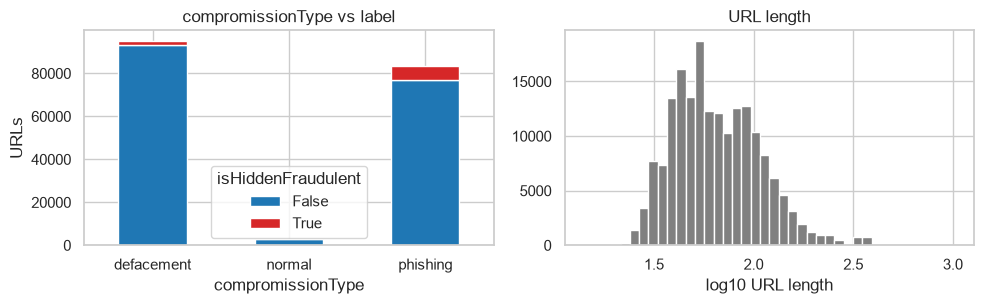

serverType     121
poweredBy       28
contentType     69 <- distinct values per categorical column


In [5]:
# Cleaning as in Sect. 7 of the paper
df = raw.drop(columns=["lastModified"]).copy()
df["poweredBy"] = df["poweredBy"].fillna(0)
df = df.dropna().reset_index(drop=True)
y = df["isHiddenFraudulent"].astype(int).to_numpy()           # 1 = hidden fraudulent URL (the positive class)
print(f"cleaned data: {len(df):,} rows x {df.shape[1]} columns, {y.sum():,} fraudulent ({y.mean():.2%})")
add_claim("data", "rows after cleaning", 181_916, len(df), 0, "rows")
add_claim("data", "fraudulent URLs after cleaning", 8_618, int(y.sum()), 0, "URLs")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
pd.crosstab(df["compromissionType"], df["isHiddenFraudulent"]).plot.bar(ax=ax[0], rot=0, stacked=True, color=["tab:blue", "tab:red"])
ax[0].set_title("compromissionType vs label"); ax[0].set_ylabel("URLs")
ax[1].hist(np.log10(df["url"].str.len()), bins=40, color="gray"); ax[1].set_xlabel("log10 URL length"); ax[1].set_title("URL length")
plt.tight_layout(); plt.show()
print(df[["serverType", "poweredBy", "contentType"]].nunique().to_string(), "<- distinct values per categorical column")

## 2. Features

**URL features (Sect. 8).** After the first tree the authors drop the four non-URL categorical columns and define new variables computed from
the URL string, giving "16 columns counting the dependent variable", i.e. 15 features. The list is only in a figure
(Fig. 4), apart from `count_http` and `count_hyphen`, which are named. The 15 below are this notebook's choice: the length
of the URL and the number of occurrences of `/ . - _ ? = @ % &`, of digits, letters and capital letters, and of the strings `http`
and `www`.

**Other columns.** `contentLength` is numeric; `compromissionType`, `serverType`, `poweredBy` and `contentType` are text and are
turned into ordinal codes (Sect. 9.2 chooses ordinal encoding for the quantum model; for the classical models the paper does not say, and ordinal
codes are the simplest option that keeps the table size at 5 non-URL columns).

**Correlation (Figs. 4-5).** Highly correlated variables are removed for the models that need it: `count_http` and `count_hyphen`
are dropped for logistic regression and the SVMs, but the decision tree and the neural networks keep the full set.

URL features: 15 | non-URL columns: 5 | full: 20 | reduced: 18


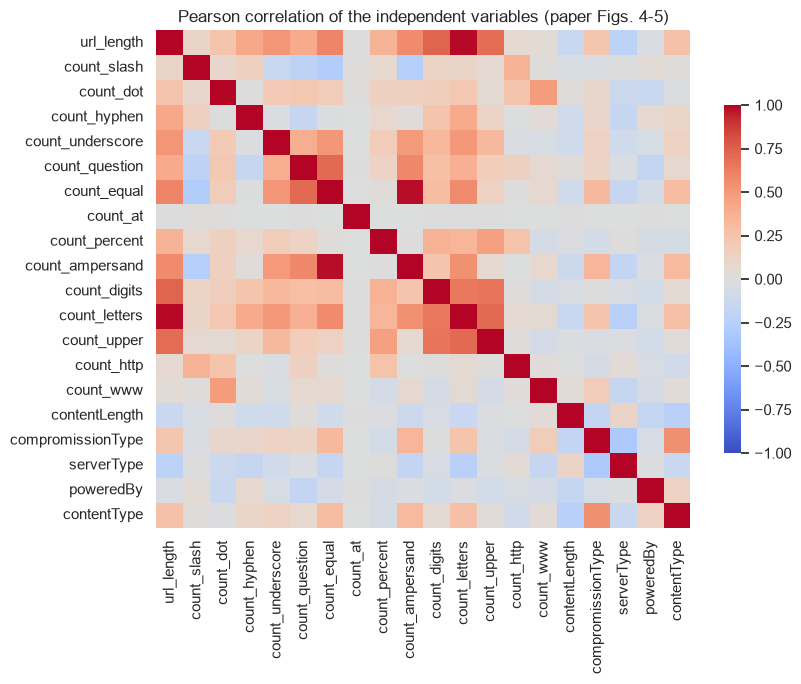

pairs with |r| > 0.9:
count_equal  count_ampersand    0.978
url_length   count_letters      0.990


In [6]:
def url_features(urls):
    # 15 numeric features computed from the URL string alone
    f = pd.DataFrame({
        "url_length":       urls.str.len(),
        "count_slash":      urls.str.count("/"),
        "count_dot":        urls.str.count(r"\."),
        "count_hyphen":     urls.str.count("-"),
        "count_underscore": urls.str.count("_"),
        "count_question":   urls.str.count(r"\?"),
        "count_equal":      urls.str.count("="),
        "count_at":         urls.str.count("@"),
        "count_percent":    urls.str.count("%"),
        "count_ampersand":  urls.str.count("&"),
        "count_digits":     urls.str.count(r"\d"),
        "count_letters":    urls.str.count("[A-Za-z]"),
        "count_upper":      urls.str.count("[A-Z]"),
        "count_http":       urls.str.count("http"),
        "count_www":        urls.str.count("www"),
    })
    return f.astype(float)

URL_F = url_features(df["url"])
CAT_COLS = ["compromissionType", "serverType", "poweredBy", "contentType"]
# CHOICE: ordinal codes; compromissionType as in the paper (normal 0, phishing 1, defacement 2), the others alphabetical.
# The codes depend only on the category names, not on the labels, so building them on all rows leaks nothing.
CODES = pd.DataFrame({"compromissionType": df["compromissionType"].map({"normal": 0, "phishing": 1, "defacement": 2})})
for c in CAT_COLS[1:]:
    CODES[c] = OrdinalEncoder().fit_transform(df[[c]].astype(str)).ravel()
CODES = CODES.astype(float)
OTHER_F = pd.concat([df[["contentLength"]].astype(float), CODES], axis=1)          # 5 non-URL columns
FULL_F  = pd.concat([URL_F, OTHER_F], axis=1)                                      # 20 columns: the DT / NN input (paper Fig. 4)
REDUCED_COLS = [c for c in FULL_F.columns if c not in ("count_http", "count_hyphen")]   # LR / SVC input (paper Fig. 5)
print("URL features:", URL_F.shape[1], "| non-URL columns:", OTHER_F.shape[1], "| full:", FULL_F.shape[1], "| reduced:", len(REDUCED_COLS))

corr = FULL_F.corr(method="pearson")
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=ax, cbar_kws=dict(shrink=.7))
ax.set_title("Pearson correlation of the independent variables (paper Figs. 4-5)"); plt.tight_layout(); plt.show()
hi = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack(); hi = hi[hi.abs() > 0.9].sort_values()
print("pairs with |r| > 0.9:\n" + hi.round(3).to_string())

## 3. Classical machine learning (Sect. 8)

All classical models use the same random split, 80 % / 20 % of the 181,916 rows, as in the paper (145,532 / 36,384 rows).
The positive class is "fraudulent". The paper's key metric is recall of the fraudulent class and, in the conclusions, the F1 score.

In [7]:
idx_train, idx_test = train_test_split(np.arange(len(df)), test_size=TEST_SIZE, random_state=SEED)   # unstratified, as "random data points"
y_tr, y_te = y[idx_train], y[idx_test]
print(f"train {len(idx_train):,} rows ({y_tr.sum():,} fraudulent) | test {len(idx_test):,} rows ({y_te.sum():,} fraudulent)")
print("paper: train 145,532 rows (6,965 fraudulent), test 36,384 rows (1,653 fraudulent)")

def prf(y_true, y_pred):
    # metrics of both classes, in percent
    return dict(accuracy=100 * accuracy_score(y_true, y_pred),
                prec_fraud=100 * precision_score(y_true, y_pred, zero_division=0), rec_fraud=100 * recall_score(y_true, y_pred),
                f1_fraud=100 * f1_score(y_true, y_pred),
                prec_ok=100 * precision_score(y_true, y_pred, pos_label=0, zero_division=0), rec_ok=100 * recall_score(y_true, y_pred, pos_label=0),
                f1_ok=100 * f1_score(y_true, y_pred, pos_label=0))

def show_cm(y_true, y_pred, title, ax=None):
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=["not fraud", "fraud"]).plot(ax=ax, cmap="Blues", colorbar=False)
    if ax is not None: ax.set_title(title)

def tree(X, name):
    t = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(X.iloc[idx_train], y_tr)
    pred = t.predict(X.iloc[idx_test]); return t, pred, prf(y_te, pred)

train 145,532 rows (6,887 fraudulent) | test 36,384 rows (1,731 fraudulent)
paper: train 145,532 rows (6,965 fraudulent), test 36,384 rows (1,653 fraudulent)


### 3.1 First experiment: a decision tree without looking at the URL (Fig. 6)

The paper first checks the "goodness of the data without the URLs": a decision tree on `contentLength`, `compromissionType`,
`serverType`, `poweredBy` and `contentType`. It reports accuracy 87.77 %; of the 1,653 test frauds 1,343 (81.25 %) were found, and 88.08 % of the not-fraud URLs.
The paper does not give the tree's depth; we use scikit-learn's default (fully grown) tree with `class_weight="balanced"`.

{'accuracy': 90.58, 'prec_fraud': 31.55, 'rec_fraud': 83.82, 'f1_fraud': 45.85, 'prec_ok': 99.12, 'rec_ok': 90.92, 'f1_ok': 94.84}


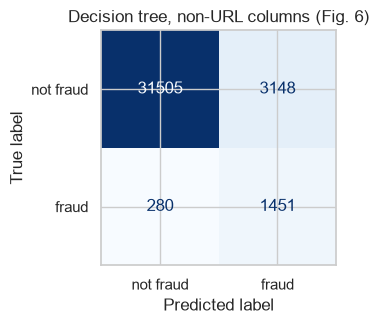

In [8]:
t1, p1, m1 = tree(OTHER_F, "non-URL")
print({k: round(v, 2) for k, v in m1.items()})
add_claim("3.1 tree, no URL", "accuracy", 87.77, m1["accuracy"], 2.0, "%")
add_claim("3.1 tree, no URL", "fraud recall", 81.25, m1["rec_fraud"], 2.0, "%")
add_claim("3.1 tree, no URL", "not-fraud recall", 88.08, m1["rec_ok"], 2.0, "%")
fig, ax = plt.subplots(figsize=(3.8, 3.4)); show_cm(y_te, p1, "Decision tree, non-URL columns (Fig. 6)", ax); plt.tight_layout(); plt.show()

### 3.2 Second experiment: a decision tree on the URL features only (Fig. 7)

Now only the 15 features computed from the URL are used. Paper: accuracy 93.18 %, fraud recall 85.96 % (232 missed), not-fraud recall 93.52 %.

{'accuracy': 90.97, 'prec_fraud': 32.37, 'rec_fraud': 82.44, 'f1_fraud': 46.48, 'prec_ok': 99.05, 'rec_ok': 91.39, 'f1_ok': 95.07} | missed frauds: 304


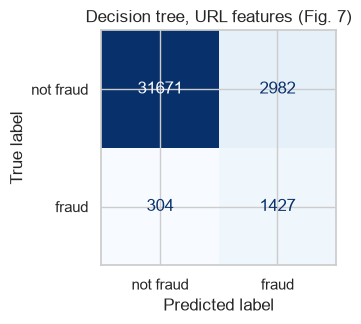

In [9]:
t2, p2, m2 = tree(URL_F, "URL only")
print({k: round(v, 2) for k, v in m2.items()}, "| missed frauds:", int(((y_te == 1) & (p2 == 0)).sum()))
add_claim("3.2 tree, URL only", "accuracy", 93.18, m2["accuracy"], 2.0, "%")
add_claim("3.2 tree, URL only", "fraud recall", 85.96, m2["rec_fraud"], 2.0, "%")
add_claim("3.2 tree, URL only", "not-fraud recall", 93.52, m2["rec_ok"], 2.0, "%")
fig, ax = plt.subplots(figsize=(3.8, 3.4)); show_cm(y_te, p2, "Decision tree, URL features (Fig. 7)", ax); plt.tight_layout(); plt.show()

### 3.3 Tables 2 and 3: logistic regression, SVC and decision tree on the combined features

The authors keep the URL features and the five other columns. Every model except the tree sees **normalised** data
(`StandardScaler`, fitted on the training rows only). The decision tree and the networks use the full set (20 columns), logistic regression and the SVMs the
reduced set without `count_http` and `count_hyphen` (18 columns). All use `class_weight="balanced"`. The paper calls the SVM "SVC" and
reports three kernels: sigmoid, polynomial and RBF. The kernel SVMs are trained on a random sub-sample of `SVC_TRAIN_CAP` training rows
(a CHOICE explained in the table at the top) and tested on the whole test set.

In [10]:
sc_red = StandardScaler().fit(FULL_F.iloc[idx_train][REDUCED_COLS])
Xr_tr = sc_red.transform(FULL_F.iloc[idx_train][REDUCED_COLS]); Xr_te = sc_red.transform(FULL_F.iloc[idx_test][REDUCED_COLS])
sub = np.random.default_rng(SEED).choice(len(idx_train), size=min(SVC_TRAIN_CAP, len(idx_train)), replace=False)   # CHOICE: sub-sample for kernel SVMs
print(f"logistic regression on {len(Xr_tr):,} rows; kernel SVMs on {len(sub):,} rows ({y_tr[sub].sum()} fraudulent)")

models, preds, scores, times = {}, {}, {}, {}
t0 = time.perf_counter()
m = LogisticRegression(class_weight="balanced", max_iter=2000).fit(Xr_tr, y_tr)
models["Logistic regression"] = m; preds["Logistic regression"] = m.predict(Xr_te); scores["Logistic regression"] = m.predict_proba(Xr_te)[:, 1]
times["Logistic regression"] = time.perf_counter() - t0
for name, kern in [("SVC (Sigmoid)", "sigmoid"), ("SVC (Poly)", "poly"), ("SVC (RBF)", "rbf")]:
    t0 = time.perf_counter()
    m = SVC(kernel=kern, class_weight="balanced", random_state=SEED).fit(Xr_tr[sub], y_tr[sub])
    models[name] = m; preds[name] = m.predict(Xr_te); scores[name] = m.decision_function(Xr_te)
    times[name] = time.perf_counter() - t0; print(f"{name}: {times[name]:.0f} s")
t_full, p_full, m_full = tree(FULL_F, "full")
models["Decision tree"] = t_full; preds["Decision tree"] = p_full; scores["Decision tree"] = t_full.predict_proba(FULL_F.iloc[idx_test])[:, 1]
times["Decision tree"] = 0.0

PAPER_T2 = {"Logistic regression": (99, 82, 89), "SVC (Sigmoid)": (97, 58, 72), "SVC (Poly)": (100, 96, 98), "SVC (RBF)": (100, 98, 99), "Decision tree": (100, 99, 100)}
PAPER_T3 = {"Logistic regression": (16, 75, 27), "SVC (Sigmoid)": (6, 59, 11), "SVC (Poly)": (55, 93, 69), "SVC (RBF)": (68, 94, 79), "Decision tree": (89, 91, 90)}
rows2, rows3 = [], []
for name in PAPER_T2:
    mm = prf(y_te, preds[name])
    rows2.append([name, *PAPER_T2[name], round(mm["prec_ok"]), round(mm["rec_ok"]), round(mm["f1_ok"])])
    rows3.append([name, *PAPER_T3[name], round(mm["prec_fraud"]), round(mm["rec_fraud"]), round(mm["f1_fraud"])])
    for lab, pp, oo in zip(("precision", "recall", "F1"), PAPER_T3[name], (mm["prec_fraud"], mm["rec_fraud"], mm["f1_fraud"])):
        add_claim("Table 3 (fraud class)", f"{name} {lab}", pp, oo, 2.0, "%")
    for lab, pp, oo in zip(("precision", "recall", "F1"), PAPER_T2[name], (mm["prec_ok"], mm["rec_ok"], mm["f1_ok"])):
        add_claim("Table 2 (not-fraud class)", f"{name} {lab}", pp, oo, 2.0, "%")
cols = pd.MultiIndex.from_product([["paper", "notebook"], ["precision", "recall", "F1"]])
T2 = pd.DataFrame([r[1:] for r in rows2], index=[r[0] for r in rows2], columns=cols)
T3 = pd.DataFrame([r[1:] for r in rows3], index=[r[0] for r in rows3], columns=cols)
print("Table 2: class 'not fraudulent' (%)"); display(T2)
print("Table 3: class 'fraudulent' (%)"); display(T3)

logistic regression on 145,532 rows; kernel SVMs on 30,000 rows (1347 fraudulent)


SVC (Sigmoid): 134 s


SVC (Poly): 35 s


SVC (RBF): 122 s


Table 2: class 'not fraudulent' (%)


paper              notebook            
                    precision recall   F1 precision recall   F1
Logistic regression        99     82   89        99     83   90
SVC (Sigmoid)              97     58   72        95     48   63
SVC (Poly)                100     96   98        99     94   97
SVC (RBF)                 100     98   99       100     94   97
Decision tree             100     99  100        99    100  100

Table 3: class 'fraudulent' (%)


paper             notebook           
                    precision recall  F1 precision recall  F1
Logistic regression        16     75  27        19     81  30
SVC (Sigmoid)               6     59  11         4     46   8
SVC (Poly)                 55     93  69        44     90  59
SVC (RBF)                  68     94  79        44     92  60
Decision tree              89     91  90        92     89  91

### 3.4 Table 4 and Figures 8-11: three neural networks

Keras models with `binary_crossentropy`, the `binary_accuracy` metric and `class_weight` balanced. Following the text: (1) one hidden layer with sigmoid
activation, `adam`; (2) three sigmoid hidden layers, `rmsprop`; (3) hidden layers with relu, relu and sigmoid activations, `adam`.
Each ends in a single sigmoid unit. A fifth of the training rows is held out as validation data to draw the accuracy curves of Fig. 11.

First neural network: 19 s


Second neural network: 20 s


Third neural network: 18 s


Table 4 (fraud class, %)


paper                  notebook                
                      precision recall accuracy precision recall accuracy
First neural network         16     77    80.99      26.3   89.3    87.56
Second neural network        41     91    93.69      26.8   90.5    87.76
Third neural network         56     95    96.35      44.4   93.9    94.12

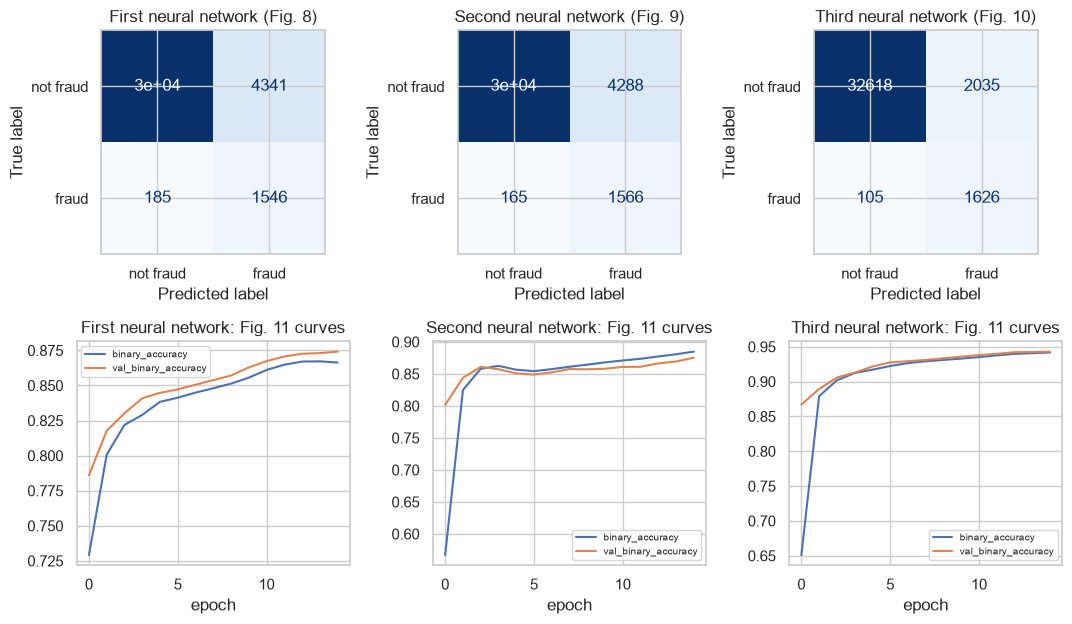

In [11]:
cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_tr); CW = {0: float(cw[0]), 1: float(cw[1])}
sc_full = StandardScaler().fit(FULL_F.iloc[idx_train])
Xf_tr = sc_full.transform(FULL_F.iloc[idx_train]); Xf_te = sc_full.transform(FULL_F.iloc[idx_test])

def build_nn(hidden, optimizer):
    # hidden: list of activation names, one Dense(NN_UNITS) layer each
    tf.keras.utils.set_random_seed(SEED)
    layers = [tf.keras.layers.Input((Xf_tr.shape[1],))] + [tf.keras.layers.Dense(NN_UNITS, activation=a) for a in hidden] + [tf.keras.layers.Dense(1, activation="sigmoid")]
    model = tf.keras.Sequential(layers)
    model.compile(optimizer=optimizer, loss="binary_crossentropy", metrics=["binary_accuracy"])
    return model

NN_SPECS = {"First neural network": (["sigmoid"], "adam"),
            "Second neural network": (["sigmoid"] * 3, "rmsprop"),
            "Third neural network": (["relu", "relu", "sigmoid"], "adam")}      # CHOICE: three hidden layers, then the output unit
nn_hist, nn_prob = {}, {}
for name, (hidden, opt) in NN_SPECS.items():
    t0 = time.perf_counter(); model = build_nn(hidden, opt)
    h = model.fit(Xf_tr, y_tr, validation_split=0.2, epochs=NN_EPOCHS, batch_size=NN_BATCH, class_weight=CW, verbose=0)
    nn_hist[name] = h.history; nn_prob[name] = model.predict(Xf_te, batch_size=4096, verbose=0).ravel()
    preds[name] = (nn_prob[name] > 0.5).astype(int); scores[name] = nn_prob[name]; times[name] = time.perf_counter() - t0
    print(f"{name}: {times[name]:.0f} s")

PAPER_T4 = {"First neural network": (16, 77, 80.99), "Second neural network": (41, 91, 93.69), "Third neural network": (56, 95, 96.35)}
rows = []
for name, (pp, pr, pa) in PAPER_T4.items():
    mm = prf(y_te, preds[name])
    rows.append([name, pp, pr, pa, round(mm["prec_fraud"], 1), round(mm["rec_fraud"], 1), round(mm["accuracy"], 2)])
    add_claim("Table 4", f"{name} fraud precision", pp, mm["prec_fraud"], 2.0, "%")
    add_claim("Table 4", f"{name} fraud recall", pr, mm["rec_fraud"], 2.0, "%")
    add_claim("Table 4", f"{name} accuracy", pa, mm["accuracy"], 2.0, "%")
cols = pd.MultiIndex.from_tuples([("paper", "precision"), ("paper", "recall"), ("paper", "accuracy"), ("notebook", "precision"), ("notebook", "recall"), ("notebook", "accuracy")])
T4 = pd.DataFrame([r[1:] for r in rows], index=[r[0] for r in rows], columns=cols); print("Table 4 (fraud class, %)"); display(T4)

fig, axs = plt.subplots(2, 3, figsize=(11, 6.4))
for k, name in enumerate(NN_SPECS):
    show_cm(y_te, preds[name], f"{name} (Fig. {8 + k})", axs[0, k])
    axs[1, k].plot(nn_hist[name]["binary_accuracy"], label="binary_accuracy"); axs[1, k].plot(nn_hist[name]["val_binary_accuracy"], label="val_binary_accuracy")
    axs[1, k].set_xlabel("epoch"); axs[1, k].set_title(f"{name}: Fig. 11 curves"); axs[1, k].legend(fontsize=7)
plt.tight_layout(); plt.show()

### 3.5 Table 5: area under the ROC curve (Figs. 2 and 11)

The ROC curve plots the true-positive rate against the false-positive rate while the decision threshold moves; the paper ranks the models by
the area under it. Scores are the model's probability (logistic regression, tree, networks) or SVM decision value.

A detail worth noticing: the paper's values are consistent with the area under the ROC curve of the **0/1 predictions**, not of the models' scores.
With hard predictions the curve has a single corner point and its area equals (recall + specificity) / 2, which is the balanced accuracy. The paper's Table 5 matches that formula for every
model it lists (e.g. logistic regression: recall 75 %, specificity about 82 %, area 78.46 %). The cell below reports both versions; the claims are judged on the 0/1 version because that is what the paper's numbers are.

,paper AUC (%),"notebook, from 0/1 predictions (%)","notebook, from scores (%)",difference (0/1)
Logistic regression,78.46,81.53,90.87,3.07
SVC (Sigmoid),58.50,46.65,47.30,-11.85
SVC (Poly),94.49,92.24,96.57,-2.25
SVC (RBF),95.86,93.22,97.81,-2.64
Decision tree,94.98,94.29,94.37,-0.69
First neural network,79.18,88.39,95.25,9.21
Second neural network,92.57,89.05,95.77,-3.52
Third neural network,95.61,94.03,98.67,-1.58


paper ranking by AUC (top three): ['SVC (RBF)', 'Third neural network', 'Decision tree'] | notebook (0/1 predictions): ['Decision tree', 'Third neural network', 'SVC (RBF)']
a ROC curve built from 0/1 predictions has one corner point, and its area equals (recall + specificity) / 2:
 paper LR: (75 + 82) / 2 = 78.5 (Table 5: 78.46); paper SVC sigmoid: (59 + 58) / 2 = 58.5 (58.50); paper SVC RBF: (94 + 98) / 2 = 96 (95.86)


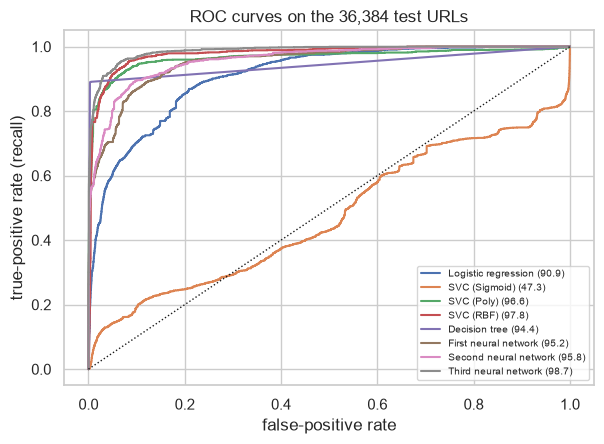

In [12]:
PAPER_T5 = {"Logistic regression": 78.46, "SVC (Sigmoid)": 58.50, "SVC (Poly)": 94.49, "SVC (RBF)": 95.86, "Decision tree": 94.98,
            "First neural network": 79.18, "Second neural network": 92.57, "Third neural network": 95.61}
auc_hard  = {k: 100 * roc_auc_score(y_te, preds[k])  for k in PAPER_T5}      # ROC of the 0/1 predictions (one operating point)
auc_score = {k: 100 * roc_auc_score(y_te, scores[k]) for k in PAPER_T5}      # ROC of the continuous scores (the textbook AUC)
T5 = pd.DataFrame({"paper AUC (%)": PAPER_T5, "notebook, from 0/1 predictions (%)": {k: round(v, 2) for k, v in auc_hard.items()},
                   "notebook, from scores (%)": {k: round(v, 2) for k, v in auc_score.items()}})
T5["difference (0/1)"] = (T5["notebook, from 0/1 predictions (%)"] - T5["paper AUC (%)"]).round(2); display(T5)
for k in PAPER_T5: add_claim("Table 5", f"AUC {k} (from 0/1 predictions)", PAPER_T5[k], auc_hard[k], 2.0, "%")
auc = auc_hard
rank_paper = ["SVC (RBF)", "Third neural network", "Decision tree"]
rank_ours = sorted(["SVC (RBF)", "Third neural network", "Decision tree"], key=lambda k: -auc[k])
print("paper ranking by AUC (top three):", rank_paper, "| notebook (0/1 predictions):", rank_ours)
print("a ROC curve built from 0/1 predictions has one corner point, and its area equals (recall + specificity) / 2:")
print(" paper LR: (75 + 82) / 2 = 78.5 (Table 5: 78.46); paper SVC sigmoid: (59 + 58) / 2 = 58.5 (58.50); paper SVC RBF: (94 + 98) / 2 = 96 (95.86)")

fig, ax = plt.subplots(figsize=(6.2, 4.6))
for k in PAPER_T5:
    fpr, tpr, _ = roc_curve(y_te, scores[k]); ax.plot(fpr, tpr, label=f"{k} ({auc_score[k]:.1f})")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("false-positive rate"); ax.set_ylabel("true-positive rate (recall)")
ax.set_title("ROC curves on the 36,384 test URLs"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()

### 3.6 Table 6: comparison with Urcuqui et al. [13]

The paper compares accuracy of its SVM and logistic regression with the same models in an earlier study of a related data set
(Urcuqui et al. 2017, different features, so only the paper's own column can be checked): 97.70 % and 81.48 %. We take "SVM" to mean the RBF SVC.

In [13]:
acc_svm, acc_lr = prf(y_te, preds["SVC (RBF)"])["accuracy"], prf(y_te, preds["Logistic regression"])["accuracy"]
T6 = pd.DataFrame({"paper, Accuracy (1) %": {"SVM": 97.70, "Logistic regression": 81.48}, "notebook %": {"SVM": round(acc_svm, 2), "Logistic regression": round(acc_lr, 2)},
                   "Urcuqui et al. [13], Accuracy (2) % (cannot be checked)": {"SVM": 97.41, "Logistic regression": 90.58}}); display(T6)
add_claim("Table 6", "SVM accuracy", 97.70, acc_svm, 2.0, "%"); add_claim("Table 6", "logistic regression accuracy", 81.48, acc_lr, 2.0, "%")

,"paper, Accuracy (1) %",notebook %,"Urcuqui et al. [13], Accuracy (2) % (cannot be checked)"
SVM,97.70,94.04,97.41
Logistic regression,81.48,82.43,90.58


### 3.7 Tables 7 and 8: a second data set (PhishDataset)

To test generalisation the authors retrain "three of the models" on the original data with only the columns the second data set also has,
then predict the second data set, the 20,000 URLs of Aung's *PhishDataset* (<https://github.com/ESDAUNG/PhishDataset>, 10,000 phishing URLs from PhishTank and 10,000
legitimate ones; label 1 = phishing). The paper writes that this set "only contains phishing URLs and the compromissionType". The file we
downloaded has just two columns (`Labels`, `URLs`), so the second data set has no `compromissionType` and the paper's wording can be read in two ways. We report both:

* **reading A:** `compromissionType` = phishing for label 1 and normal for label 0;
* **reading B:** `compromissionType` = phishing for every row.

The models are trained on the original training rows with the URL features plus `compromissionType` (16 columns). Ground truth for the
second data set is its phishing label. The paper's Table 7 is the performance on the original test rows with this reduced input
and Table 8 the performance on the second data set (the paper lists three of the four models as "trained with the original set").

In [14]:
PHISH_URL = "https://raw.githubusercontent.com/ESDAUNG/PhishDataset/main/data_bal%20-%2020000.xlsx"
def read_xlsx_two_columns(path_or_bytes):
    # Minimal .xlsx reader (standard library only): returns the rows of the first sheet as (A, B) string pairs.
    import xml.etree.ElementTree as ET
    ns = "{http://schemas.openxmlformats.org/spreadsheetml/2006/main}"
    z = zipfile.ZipFile(io.BytesIO(path_or_bytes) if isinstance(path_or_bytes, bytes) else path_or_bytes)
    sst = ["".join(t.text or "" for t in si.iter(ns + "t")) for si in ET.fromstring(z.read("xl/sharedStrings.xml")).iter(ns + "si")]
    out = []
    for row in ET.fromstring(z.read("xl/worksheets/sheet1.xml")).iter(ns + "row"):
        cells = {}
        for c in row.iter(ns + "c"):
            v = c.find(ns + "v")
            if v is not None: cells[c.get("r").rstrip("0123456789")] = sst[int(v.text)] if c.get("t") == "s" else v.text
        out.append((cells.get("A"), cells.get("B")))
    return out

xlsx_path = os.path.join(DATA_DIR, "PhishDataset_data_bal_20000.xlsx")
if not os.path.exists(xlsx_path):
    r = requests.get(PHISH_URL, timeout=60); r.raise_for_status(); open(xlsx_path, "wb").write(r.content)
rows = read_xlsx_two_columns(xlsx_path)
phish = pd.DataFrame(rows[1:], columns=["label", "url"]).dropna(); phish["label"] = phish["label"].astype(float).astype(int)
print(phish.shape, phish["label"].value_counts().to_dict()); display(phish.head(3))

(20000, 2) {1: 10000, 0: 10000}


,label,url
0,1,http://dbs.vote-friend.com/sg?ref=anything
1,0,https://www.reynoldstransfer.com/versa-lift-fo...
2,1,https://www.halisupportservice.com/Login.php


In [15]:
RED_COLS = list(URL_F.columns) + ["compromissionType"]
RED = pd.concat([URL_F, CODES[["compromissionType"]]], axis=1)[RED_COLS]
sc_red2 = StandardScaler().fit(RED.iloc[idx_train]); R_tr = sc_red2.transform(RED.iloc[idx_train]); R_te = sc_red2.transform(RED.iloc[idx_test])
PH_URL = url_features(phish["url"])
readings = {"A (type follows label)": np.where(phish["label"] == 1, 1.0, 0.0), "B (all phishing)": np.ones(len(phish))}
PH_X = {k: sc_red2.transform(pd.concat([PH_URL, pd.Series(v, name="compromissionType")], axis=1)[RED_COLS]) for k, v in readings.items()}

red_models, red_pred_te, red_pred_ph = {}, {}, {}
t_red = DecisionTreeClassifier(class_weight="balanced", random_state=SEED).fit(RED.iloc[idx_train], y_tr)
red_models["Decision tree"] = (t_red, False)
tf.keras.utils.set_random_seed(SEED)
nn_red = tf.keras.Sequential([tf.keras.layers.Input((R_tr.shape[1],))] + [tf.keras.layers.Dense(NN_UNITS, activation=a) for a in ["relu", "relu", "sigmoid"]] + [tf.keras.layers.Dense(1, activation="sigmoid")])
nn_red.compile(optimizer="adam", loss="binary_crossentropy", metrics=["binary_accuracy"])
nn_red.fit(R_tr, y_tr, epochs=NN_EPOCHS, batch_size=NN_BATCH, class_weight=CW, verbose=0)
svm_poly = SVC(kernel="poly", class_weight="balanced", random_state=SEED).fit(R_tr[sub], y_tr[sub])
svm_rbf  = SVC(kernel="rbf",  class_weight="balanced", random_state=SEED).fit(R_tr[sub], y_tr[sub])

def predict_red(name, X_std, X_raw):
    if name == "Decision tree":          return t_red.predict(X_raw)
    if name == "Third neural network":   return (nn_red.predict(X_std, batch_size=4096, verbose=0).ravel() > 0.5).astype(int)
    return (svm_poly if name == "SVM (Poly)" else svm_rbf).predict(X_std)

PAPER_T7 = {"Decision tree": (50, 91, 95.43), "Third neural network": (38, 95, 92.85), "SVM (Poly)": (30, 94, 90.01), "SVM (RBF)": (37, 95, 92.48)}
PAPER_T8 = {"Decision tree": (46, 75, 42.95), "Third neural network": (46, 85, 43.29), "SVM (Poly)": (47, 75, 44.81), "SVM (RBF)": (49, 87, 47.33)}
r7, r8 = [], []
for name in PAPER_T7:
    p_te = predict_red(name, R_te, RED.iloc[idx_test]); m7 = prf(y_te, p_te)
    r7.append(dict(model=name, **{"paper prec": PAPER_T7[name][0], "paper rec": PAPER_T7[name][1], "paper acc": PAPER_T7[name][2]},
                   **{"nb prec": round(m7["prec_fraud"]), "nb rec": round(m7["rec_fraud"]), "nb acc": round(m7["accuracy"], 2)}))
    add_claim("Table 7", f"{name} fraud recall", PAPER_T7[name][1], m7["rec_fraud"], 2.0, "%")
    add_claim("Table 7", f"{name} accuracy", PAPER_T7[name][2], m7["accuracy"], 2.0, "%")
    for k in readings:
        Xr_raw = pd.concat([PH_URL, pd.Series(readings[k], name="compromissionType")], axis=1)[RED_COLS]
        m8 = prf(phish["label"].to_numpy(), predict_red(name, PH_X[k], Xr_raw))
        r8.append(dict(model=name, reading=k, **{"paper prec": PAPER_T8[name][0], "paper rec": PAPER_T8[name][1], "paper acc": PAPER_T8[name][2]},
                       **{"nb prec": round(m8["prec_fraud"]), "nb rec": round(m8["rec_fraud"]), "nb acc": round(m8["accuracy"], 2)}))
print("Table 7: reduced columns, original test rows (%)"); display(pd.DataFrame(r7).set_index("model"))
T8 = pd.DataFrame(r8).set_index(["model", "reading"]); print("Table 8: PhishDataset (%)"); display(T8)
# Table 8 cannot be checked: the paper's own description of the second data set is inconsistent with its numbers (see the text); the numbers of the reading closest to the paper are listed for completeness
for name in PAPER_T8:
    best = min((abs(T8.loc[(name, k), "nb acc"] - PAPER_T8[name][2]), k) for k in readings)[1]
    add_claim("Table 8", f"{name} accuracy on PhishDataset (closest reading: {best[0]})", PAPER_T8[name][2], float(T8.loc[(name, best), "nb acc"]), 2.0, "%", verdict="cannot be checked")
    add_claim("Table 8", f"{name} recall on PhishDataset (closest reading: {best[0]})", PAPER_T8[name][1], float(T8.loc[(name, best), "nb rec"]), 2.0, "%", verdict="cannot be checked")

Table 7: reduced columns, original test rows (%)


,paper prec,paper rec,paper acc,nb prec,nb rec,nb acc
model,,,,,,
Decision tree,50,91,95.43,46,86,94.45
Third neural network,38,95,92.85,32,93,90.11
SVM (Poly),30,94,90.01,25,90,86.79
SVM (RBF),37,95,92.48,26,91,87.08


Table 8: PhishDataset (%)


paper prec  paper rec  paper acc  \
model                reading                                                    
Decision tree        A (type follows label)          46         75      42.95   
                     B (all phishing)                46         75      42.95   
Third neural network A (type follows label)          46         85      43.29   
                     B (all phishing)                46         85      43.29   
SVM (Poly)           A (type follows label)          47         75      44.81   
                     B (all phishing)                47         75      44.81   
SVM (RBF)            A (type follows label)          49         87      47.33   
                     B (all phishing)                49         87      47.33   

                                             nb prec  nb rec  nb acc  
model                reading                                          
Decision tree        A (type follows label)       94      50   73.42  
                     B (all phishing)             74      50   66.16  
Third neural network A (type follows label)       97      68   83.03  
                     B (all phishing)             83      68   77.35  
SVM (Poly)           A (type follows label)       95      67   81.98  
                     B (all phishing)             92      67   80.81  
SVM (RBF)            A (type follows label)       98      74   86.20  
                     B (all phishing)             91      74   83.41

## 4. Quantum machine learning (Sect. 9)

### 4.1 The 200-URL sample and the six numeric features

For the quantum model all features must be numeric and few: one feature per qubit. The paper keeps six: the number of characters of the URL, `compromissionType`
(phishing 1, defacement 2, normal 0), `contentLength` and the ordinal codes of `serverType`, `poweredBy` and `contentType`. Because simulating
a quantum circuit for every URL is slow, a first approximation uses **200 URLs: 100 fraudulent and 100 not**.

Preprocessing, all fitted on the training part only: `log1p` on the heavy-tailed `contentLength`, then a `MinMaxScaler` onto $[0,\pi]$ (so that features are rotation
angles); test values outside the training range are clipped to $[0,\pi]$. The paper does not describe any scaling, so this is a
CHOICE; Section 4.9 shows what happens without it.

In [16]:
Q_FEATURES = pd.DataFrame({"url_length": URL_F["url_length"], "compromissionType": CODES["compromissionType"],
                           "log1p_contentLength": np.log1p(OTHER_F["contentLength"]),      # CHOICE: log1p of the heavy-tailed length
                           "serverType": CODES["serverType"], "poweredBy": CODES["poweredBy"], "contentType": CODES["contentType"]})
assert Q_FEATURES.shape[1] == N_QUBITS

def make_quantum_data(seed, n_samples=N_SAMPLES, test_size=Q_TEST_SIZE):
    # balanced sample of n_samples URLs, stratified split, scaling fitted on the training part only
    g = np.random.default_rng(seed)
    pos = g.choice(np.where(y == 1)[0], n_samples // 2, replace=False); neg = g.choice(np.where(y == 0)[0], n_samples // 2, replace=False)
    idx = np.concatenate([pos, neg]); Xq = Q_FEATURES.iloc[idx].to_numpy(float); yq = y[idx]
    Xtr, Xte, ytr, yte = train_test_split(Xq, yq, test_size=test_size, stratify=yq, random_state=seed)
    sc = MinMaxScaler((0, np.pi)).fit(Xtr)
    return dict(X_train=sc.transform(Xtr), X_test=np.clip(sc.transform(Xte), 0, np.pi), y_train=ytr, y_test=yte, raw_train=Xtr, raw_test=Xte, idx=idx, scaler=sc)

D = make_quantum_data(SEED)
print("train", D["X_train"].shape, np.bincount(D["y_train"]), "| test", D["X_test"].shape, np.bincount(D["y_test"]))
display(pd.DataFrame(D["X_train"][:5], columns=Q_FEATURES.columns).round(2))

train (160, 6) [80 80] | test (40, 6) [20 20]


,url_length,compromissionType,log1p_contentLength,serverType,poweredBy,contentType
0,0.08,0.0,0.0,0.00,2.40,0.26
1,1.02,0.0,0.0,0.63,0.00,1.44
2,0.12,0.0,0.0,1.07,2.59,0.26
3,1.02,0.0,0.0,0.63,0.00,1.44
4,1.08,0.0,0.0,0.26,2.40,0.26


### 4.2 Classical SVC on the 200-URL sample (Fig. 12)

Before any quantum model, the paper compares a classical `SVC` on the complete data set (train 0.97, test 0.97) and on the 200-URL sample
(train 0.91, test 0.97, confusion matrix in Fig. 12). We train `SVC()` (RBF kernel, default settings) on the six scaled features of the 200-URL sample. For "the complete data
set" we take the six features of all training rows (with the same transformation fitted on them and, for speed, at most `SVC_TRAIN_CAP` rows).

classical SVC, 200-URL sample : train 0.83  test 0.75   (paper 0.91 / 0.97)
classical SVC, whole data set  : train 0.97  test 0.97   (paper 0.97 / 0.97; note: the whole data set is 95 % not-fraud)


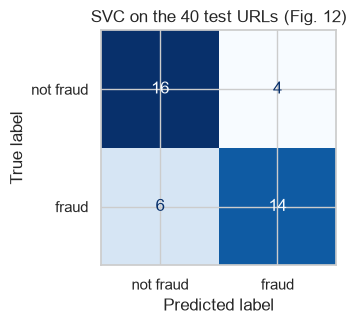

In [17]:
svc_small = SVC(random_state=SEED).fit(D["X_train"], D["y_train"])
tr_small, te_small = svc_small.score(D["X_train"], D["y_train"]), svc_small.score(D["X_test"], D["y_test"])
# SVC on the whole data set, same six features (CHOICE: capped training rows, scaled with a scaler fitted on them)
sc_all = MinMaxScaler((0, np.pi)).fit(Q_FEATURES.iloc[idx_train[sub]])
svc_all = SVC(random_state=SEED).fit(sc_all.transform(Q_FEATURES.iloc[idx_train[sub]]), y_tr[sub])
tr_all = svc_all.score(sc_all.transform(Q_FEATURES.iloc[idx_train[sub]]), y_tr[sub])
te_all = svc_all.score(np.clip(sc_all.transform(Q_FEATURES.iloc[idx_test]), 0, np.pi), y_te)
print(f"classical SVC, 200-URL sample : train {tr_small:.2f}  test {te_small:.2f}   (paper 0.91 / 0.97)")
print(f"classical SVC, whole data set  : train {tr_all:.2f}  test {te_all:.2f}   (paper 0.97 / 0.97; note: the whole data set is 95 % not-fraud)")
add_claim("4.2 SVC sample", "SVC train score, 200 URLs", 0.91, tr_small, 0.02); add_claim("4.2 SVC sample", "SVC test score, 200 URLs", 0.97, te_small, 0.02)
add_claim("4.2 SVC full", "SVC train score, whole data", 0.97, tr_all, 0.02); add_claim("4.2 SVC full", "SVC test score, whole data", 0.97, te_all, 0.02)
fig, ax = plt.subplots(figsize=(3.8, 3.4)); show_cm(D["y_test"], svc_small.predict(D["X_test"]), "SVC on the 40 test URLs (Fig. 12)", ax); plt.tight_layout(); plt.show()

### 4.3 Feature maps and ansaetze (Figs. 13 and 14)

A **feature map** writes the six angles of a URL into the state of six qubits. The paper tries three:
`ZFeatureMap` (Hadamards then one phase rotation per qubit, no entanglement), `ZZFeatureMap` (adds phases that depend on pairs of
features) and `PauliFeatureMap`. An **ansatz** is the trainable part: layers of single-qubit rotations and entangling gates whose angles $\theta$ the optimiser changes. The paper tries
`RealAmplitudes` (only $R_Y$ rotations), `EfficientSU2` ($R_Y$ and $R_Z$) and `ExcitationPreserving`. The VQC measures all six qubits and
reads the class from the parity of the bit string (Qiskit's default).

Two remarks. (1) With six qubits and 2 repetitions `RealAmplitudes` has $6\times 3 = 18$ parameters, $\theta[0]\dots\theta[17]$; the paper's "17 parameters
$\theta[1]\dots\theta[17]$" is the highest index, so six qubits is confirmed. (2) `PauliFeatureMap`'s default Pauli strings are `["Z","ZZ"]`, which is exactly `ZZFeatureMap`; a cell in Section 4.4 checks that
the two give identical states. Their separate rows in the paper (Tables 9 and 11) can therefore differ only through random
initial values, which tells us how large the run-to-run noise is.

ZFeatureMap: 6 input parameters, depth 4
ZZFeatureMap: 6 input parameters, depth 49
PauliFeatureMap: 6 input parameters, depth 49
RealAmplitudes(reps=2): 18 trainable parameters, depth 10
EfficientSU2(reps=2): 36 trainable parameters, depth 13
ExcitationPreserving(reps=2): 48 trainable parameters, depth 18


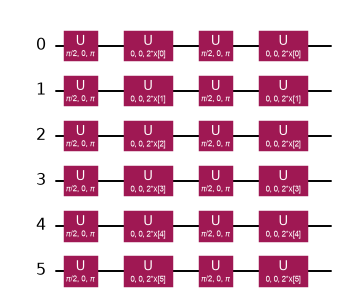

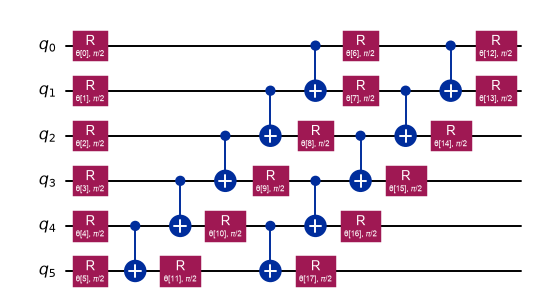

In [18]:
def make_feature_map(name, n=N_QUBITS):
    # CHOICE: library defaults (2 repetitions); the paper does not state them
    return {"ZFeatureMap": z_feature_map, "ZZFeatureMap": zz_feature_map, "PauliFeatureMap": pauli_feature_map}[name](n)

def make_ansatz(name, n=N_QUBITS, reps=2):
    return {"RealAmplitudes": real_amplitudes, "EfficientSU2": efficient_su2, "ExcitationPreserving": excitation_preserving}[name](n, reps=reps)

for name in ["ZFeatureMap", "ZZFeatureMap", "PauliFeatureMap"]:
    fm = make_feature_map(name); print(f"{name}: {fm.num_parameters} input parameters, depth {fm.decompose().depth()}")
for name in ANSAETZE:
    an = make_ansatz(name); print(f"{name}(reps=2): {an.num_parameters} trainable parameters, depth {an.decompose().depth()}")

fig_fm = make_feature_map("ZFeatureMap").decompose().draw("mpl", fold=-1, scale=0.7); display(fig_fm)         # Fig. 13
fig_an = make_ansatz("RealAmplitudes").decompose().draw("mpl", fold=-1, scale=0.7); display(fig_an)          # Fig. 14

### 4.4 A fast exact simulator for the VQC

Qiskit's `VQC` is a `SamplerQNN` (the circuit is run by a *Sampler* primitive) wrapped in a `NeuralNetworkClassifier`. With six qubits,
160 training URLs and 18-48 parameters, the stock exact sampler of `qiskit-machine-learning` needs about 10 minutes **per gradient** on a laptop
CPU (a gradient is two circuits per parameter per URL), so the 18 gradient-based combinations of the grid would take days. The paper reports
hours per combination on a MacBook M2 and a PC.

To make the full grid affordable without changing the mathematics we replace only the sampler: `FastExactVQC` is Qiskit's `VQC` whose network
evaluates the circuit with a small batched statevector simulator written in PyTorch. Every URL of the batch is simulated at once,
and PyTorch's automatic differentiation gives the **exact** gradient of the class probabilities (what parameter-shift computes). The model class, loss
(cross entropy), optimiser, `fit`, `score` and `predict` are Qiskit's own. The cell after the class proves the equivalence: forward values and
gradients agree with Qiskit's reference exact sampler (`QMLSampler`) to better than $10^{-9}$ for all nine feature-map / ansatz pairs.

In [19]:
SIM_BASIS = ["rx", "ry", "rz", "p", "h", "x", "cx"]

class BatchedStatevector:
    # Exact batched statevector simulation of a parameterised circuit in PyTorch (autograd gives exact gradients).
    def __init__(self, circuit, input_params, weight_params):
        import sympy
        self.n, self.n_in, self.n_w = circuit.num_qubits, len(input_params), len(weight_params)
        col = {p.name: i for i, p in enumerate(list(input_params) + list(weight_params))}
        tc = transpile(circuit, basis_gates=SIM_BASIS, optimization_level=0)
        self.ops = []
        for inst in tc.data:
            name, qs = inst.operation.name, [tc.find_bit(q).index for q in inst.qubits]
            if name in ("barrier", "measure"): continue
            if name not in SIM_BASIS: raise ValueError(f"unsupported gate {name}")
            angle = None
            if inst.operation.params:
                p = inst.operation.params[0]
                if isinstance(p, ParameterExpression) and p.parameters:
                    syms, idx = [sympy.Symbol(q.name) for q in p.parameters], [col[q.name] for q in p.parameters]
                    f = sympy.lambdify(syms, p.sympify(), modules="numpy", dummify=True)
                    angle = (lambda f, idx: (lambda theta: f(*[theta[:, i] for i in idx])))(f, idx)
                else:
                    angle = (lambda v: (lambda theta: v))(float(p))
            self.ops.append((name, qs, angle))

    def probabilities(self, theta):
        # theta: (B, n_in + n_w) float64 tensor -> (B, 2**n) outcome probabilities (qubit 0 = least significant bit, as in Qiskit)
        B, n = theta.shape[0], self.n
        st = torch.zeros(B, 2 ** n, dtype=torch.complex128); st[:, 0] = 1
        ar = torch.arange(2 ** n)
        for name, qs, angle in self.ops:
            if name == "cx":
                c, t = qs; st = st[:, torch.where(((ar >> c) & 1) == 1, ar ^ (1 << t), ar)]; continue
            if name == "x":
                st = st[:, ar ^ (1 << qs[0])]; continue
            q = qs[0]
            if name == "h":
                U = (torch.tensor([[1, 1], [1, -1]], dtype=torch.complex128) / math.sqrt(2)).expand(B, 2, 2)
            else:
                a = angle(theta); a = a if torch.is_tensor(a) else torch.full((B,), float(a), dtype=torch.float64)
                z = torch.zeros_like(a)
                if name == "ry":
                    c_, s_ = torch.cos(a / 2), torch.sin(a / 2); U = torch.stack([torch.stack([c_, -s_], -1), torch.stack([s_, c_], -1)], -2).to(torch.complex128)
                elif name == "rx":
                    c_, s_ = torch.cos(a / 2).to(torch.complex128), torch.sin(a / 2).to(torch.complex128)
                    U = torch.stack([torch.stack([c_, -1j * s_], -1), torch.stack([-1j * s_, c_], -1)], -2)
                elif name == "rz":
                    e = torch.exp(-0.5j * a); U = torch.stack([torch.stack([e, z.to(e.dtype)], -1), torch.stack([z.to(e.dtype), e.conj()], -1)], -2)
                else:   # "p"
                    e = torch.exp(1j * a); U = torch.stack([torch.stack([torch.ones_like(e), z.to(e.dtype)], -1), torch.stack([z.to(e.dtype), e], -1)], -2)
            st = torch.einsum("bij,bajc->baic", U, st.reshape(B, 2 ** (n - q - 1), 2, 2 ** q)).reshape(B, 2 ** n)
        return (st.conj() * st).real

class FastExactVQC(VQC):
    # Qiskit's VQC with the Sampler primitive replaced by the exact batched simulator above (same maths, much faster).
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        qnn, self._sim = self._neural_network, BatchedStatevector(self._circuit, self.feature_map.parameters, self.ansatz.parameters)
        sim = self._sim
        def class_matrix():            # outcome integer -> class index, using the network's own (parity) interpret function
            M = np.zeros((2 ** sim.n, int(np.prod(qnn.output_shape))))
            for k in range(2 ** sim.n): M[k, int(qnn._interpret(k))] = 1.0
            return torch.tensor(M)
        def fwd(input_data, weights):
            X = torch.tensor(np.asarray(input_data, float)); theta = torch.cat([X, torch.tensor(np.asarray(weights, float)).expand(X.shape[0], -1)], 1)
            with torch.no_grad(): return (sim.probabilities(theta) @ class_matrix()).numpy()
        def bwd(input_data, weights):
            X = torch.tensor(np.asarray(input_data, float))
            W = torch.tensor(np.asarray(weights, float)).expand(X.shape[0], -1).clone().requires_grad_(True)
            P = sim.probabilities(torch.cat([X, W], 1)) @ class_matrix()
            g = [torch.autograd.grad(P[:, c].sum(), W, retain_graph=True)[0] for c in range(P.shape[1])]
            return None, torch.stack(g, 1).numpy()
        qnn._forward, qnn._backward = fwd, bwd

In [20]:
# Equivalence check against Qiskit's own exact sampler (QMLSampler) on a few URLs, for all nine feature-map / ansatz pairs
chk_rng = np.random.default_rng(0); Xchk = chk_rng.uniform(0, np.pi, (2, N_QUBITS))
rows = []
for fmn in ["ZFeatureMap", "ZZFeatureMap", "PauliFeatureMap"]:
    for ann in ANSAETZE:
        fast = FastExactVQC(feature_map=make_feature_map(fmn), ansatz=make_ansatz(ann), optimizer=COBYLA(maxiter=1))
        ref  = VQC(feature_map=make_feature_map(fmn), ansatz=make_ansatz(ann), optimizer=COBYLA(maxiter=1), sampler=QMLSampler())
        w = chk_rng.uniform(0, 3, fast.ansatz.num_parameters)
        e_f = np.abs(fast.neural_network.forward(Xchk, w) - ref.neural_network.forward(Xchk, w)).max()
        e_g = np.abs(fast.neural_network.backward(Xchk, w)[1] - ref.neural_network.backward(Xchk, w)[1]).max()
        rows.append((fmn, ann, e_f, e_g))
chk = pd.DataFrame(rows, columns=["feature map", "ansatz", "max |forward diff|", "max |gradient diff|"])
display(chk.style.format({"max |forward diff|": "{:.1e}", "max |gradient diff|": "{:.1e}"}))
assert chk[["max |forward diff|", "max |gradient diff|"]].to_numpy().max() < 1e-8, "fast simulator disagrees with Qiskit's exact sampler"
# ZZFeatureMap and PauliFeatureMap with default Pauli strings are the same circuit:
a, b = (FastExactVQC(feature_map=make_feature_map(n), ansatz=make_ansatz("RealAmplitudes"), optimizer=COBYLA(maxiter=1)) for n in ("ZZFeatureMap", "PauliFeatureMap"))
th = torch.tensor(np.hstack([Xchk, chk_rng.uniform(0, 3, (2, 18))]))
print("ZZFeatureMap and PauliFeatureMap(default) give identical probabilities:", bool(torch.allclose(a._sim.probabilities(th), b._sim.probabilities(th))))

,feature map,ansatz,max |forward diff|,max |gradient diff|
0,ZFeatureMap,RealAmplitudes,4.5e-12,7.1e-12
1,ZFeatureMap,EfficientSU2,8.4e-13,5.0e-12
2,ZFeatureMap,ExcitationPreserving,3.6e-12,1.0e-11
3,ZZFeatureMap,RealAmplitudes,2.1e-12,6.1e-12
4,ZZFeatureMap,EfficientSU2,7.0e-12,7.2e-12
5,ZZFeatureMap,ExcitationPreserving,1.6e-12,4.9e-12
6,PauliFeatureMap,RealAmplitudes,2.2e-12,5.2e-12
7,PauliFeatureMap,EfficientSU2,1.8e-12,7.4e-12
8,PauliFeatureMap,ExcitationPreserving,2.7e-12,6.6e-12


ZZFeatureMap and PauliFeatureMap(default) give identical probabilities: True


### 4.5 Training the paper's best model: ZFeatureMap, RealAmplitudes (reps=2), SLSQP, 20 iterations (Fig. 15)

The paper highlights this combination: training score 0.89, test score 0.97 on the 200-URL sample. `vqc.score` is plain accuracy. We train it
once with a live loss curve, then draw its confusion matrix on the 40 test URLs.

VQC (ZFeatureMap, RealAmplitudes reps=2, SLSQP, 20 iterations): train 0.81, test 0.80 | 21 objective evaluations, 5.7 s   (paper: 0.89 / 0.97)


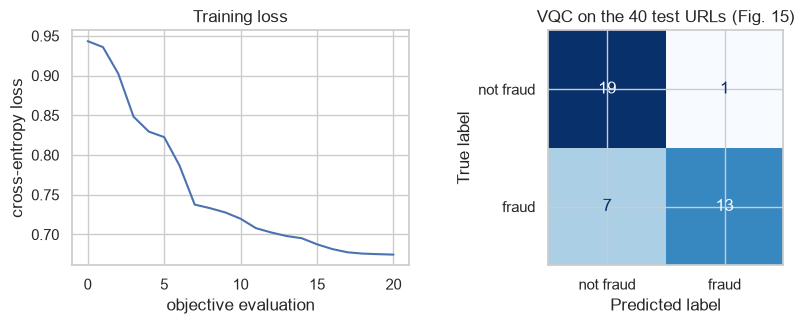

In [21]:
def make_optimizer(name, maxiter=MAXITER):
    return {"COBYLA": lambda: COBYLA(maxiter=maxiter), "SLSQP": lambda: SLSQP(maxiter=maxiter),
            "GradientDescent": lambda: GradientDescent(maxiter=maxiter)}[name]()      # CHOICE: GradientDescent keeps Qiskit's default learning rate 0.01

def train_vqc(fm_name, an_name, opt_name, data, init_seed, maxiter=MAXITER, callback=None):
    # one training run; init_seed fixes the random initial weights
    algorithm_globals.random_seed = init_seed
    obj_losses, step_losses = [], []
    def cb(*args):
        # COBYLA / SLSQP call callback(weights, loss); GradientDescent calls its own callback(nfev, weights, loss, stepsize)
        if len(args) == 2:
            obj_losses.append(float(args[1]))
            if callback: callback(*args)
        else:
            step_losses.append(float(args[2]))
            if callback and not obj_losses: callback(args[1], args[2])
    vqc = FastExactVQC(feature_map=make_feature_map(fm_name), ansatz=make_ansatz(an_name), optimizer=make_optimizer(opt_name, maxiter), callback=cb)
    t0 = time.perf_counter(); vqc.fit(data["X_train"], data["y_train"]); secs = time.perf_counter() - t0
    losses = obj_losses if obj_losses else step_losses
    return dict(model=vqc, train=vqc.score(data["X_train"], data["y_train"]), test=vqc.score(data["X_test"], data["y_test"]), seconds=secs, evaluations=len(losses), losses=losses)

def live_plot(title, every=3):
    hist = []
    def callback(weights, loss):
        hist.append(loss)
        if len(hist) % every == 0:
            clear_output(wait=True); plt.figure(figsize=(6, 2.8)); plt.plot(hist); plt.xlabel("objective evaluation"); plt.ylabel("cross-entropy loss"); plt.title(title); plt.show()
    return callback

import warnings as _w
with _w.catch_warnings():
    _w.simplefilter("ignore")          # scipy's COBYLA warns when maxiter < number of parameters + 2
    best = train_vqc("ZFeatureMap", "RealAmplitudes", "SLSQP", D, init_seed=SEED, callback=live_plot("ZFeatureMap + RealAmplitudes + SLSQP"))
clear_output(wait=True)
print(f"VQC (ZFeatureMap, RealAmplitudes reps=2, SLSQP, {MAXITER} iterations): train {best['train']:.2f}, test {best['test']:.2f} "
      f"| {best['evaluations']} objective evaluations, {best['seconds']:.1f} s   (paper: 0.89 / 0.97)")
add_claim("4.5 best VQC (seed 42)", "train score", 0.89, best["train"], 0.02); add_claim("4.5 best VQC (seed 42)", "test score", 0.97, best["test"], 0.02)
fig, ax = plt.subplots(1, 2, figsize=(8.6, 3.4))
ax[0].plot(best["losses"]); ax[0].set_xlabel("objective evaluation"); ax[0].set_ylabel("cross-entropy loss"); ax[0].set_title("Training loss")
show_cm(D["y_test"], best["model"].predict(D["X_test"]), "VQC on the 40 test URLs (Fig. 15)", ax[1]); plt.tight_layout(); plt.show()

### 4.6 The 27-combination grid (Tables 9, 10, 11)

Every combination of feature map, ansatz and optimiser is trained for 20 iterations. The paper ran each combination once; we run each combination on `GRID_SEEDS`
(each seed draws a new 200-URL sample, a new split and new random initial weights) and report the first seed next to the paper's numbers and the mean and standard deviation over seeds. Because a test set of 40 URLs has a resolution of
0.025, single-run differences of a few points are noise.

`PauliFeatureMap` runs use initial weights from `seed + 1000`, as an independent run of the same circuit as `ZZFeatureMap` (Section 4.3).
In FAST mode only the ZFeatureMap rows of the grid are computed.

In [22]:
PAPER_GRID = {   # (train, test, seconds on PC, seconds on Mac) from Tables 9-11; rows are (ansatz, optimiser)
 "ZZFeatureMap": {("RealAmplitudes","COBYLA"):(.79,.82,87,127), ("RealAmplitudes","GradientDescent"):(.21,.28,1328,536), ("RealAmplitudes","SLSQP"):(.80,.85,1284,536),
   ("EfficientSU2","COBYLA"):(.74,.72,97,26), ("EfficientSU2","GradientDescent"):(.52,.65,2900,1189), ("EfficientSU2","SLSQP"):(.84,.82,2942,1192),
   ("ExcitationPreserving","COBYLA"):(.72,.78,117,33), ("ExcitationPreserving","GradientDescent"):(.28,.17,7439,5323), ("ExcitationPreserving","SLSQP"):(.82,.80,7442,3129)},
 "ZFeatureMap": {("RealAmplitudes","COBYLA"):(.81,.95,26,11), ("RealAmplitudes","GradientDescent"):(.47,.72,571,234), ("RealAmplitudes","SLSQP"):(.89,.97,472,193),
   ("EfficientSU2","COBYLA"):(.55,.30,38,15), ("EfficientSU2","GradientDescent"):(.53,.78,1470,584), ("EfficientSU2","SLSQP"):(.80,.78,2185,585),
   ("ExcitationPreserving","COBYLA"):(.49,.75,53,22), ("ExcitationPreserving","GradientDescent"):(.46,.70,4651,7769), ("ExcitationPreserving","SLSQP"):(.90,.95,4871,1807)},
 "PauliFeatureMap": {("RealAmplitudes","COBYLA"):(.65,.85,87,22), ("RealAmplitudes","GradientDescent"):(.28,.25,1228,11019), ("RealAmplitudes","SLSQP"):(.80,.85,1258,541),
   ("EfficientSU2","COBYLA"):(.74,.72,98,27), ("EfficientSU2","GradientDescent"):(.30,.25,2749,12922), ("EfficientSU2","SLSQP"):(.84,.82,2824,1204),
   ("ExcitationPreserving","COBYLA"):(.72,.78,118,33), ("ExcitationPreserving","GradientDescent"):(.28,.17,7410,7887), ("ExcitationPreserving","SLSQP"):(.82,.80,7516,3094)}}

DATA_BY_SEED = {s: make_quantum_data(s) for s in set(GRID_SEEDS) | set(range(SEED, SEED + HEADLINE_SEEDS))}
GRID = []          # one row per (feature map, ansatz, optimiser, seed)
t_grid = time.perf_counter()
with _w.catch_warnings():
    _w.simplefilter("ignore")
    for fmn in FEATURE_MAPS:
        for ann in ANSAETZE:
            for opt in OPTIMIZERS:
                for s in GRID_SEEDS:
                    r = train_vqc(fmn, ann, opt, DATA_BY_SEED[s], init_seed=s + (1000 if fmn == "PauliFeatureMap" else 0))
                    GRID.append(dict(feature_map=fmn, ansatz=ann, optimizer=opt, seed=s, train=r["train"], test=r["test"], seconds=r["seconds"], evaluations=r["evaluations"],
                                     loss_start=r["losses"][0], loss_end=r["losses"][-1]))
                print(f"{fmn:16s} {ann:21s} {opt:15s} " + " ".join(f"s{g['seed']}: {g['train']:.2f}/{g['test']:.2f}" for g in GRID[-len(GRID_SEEDS):]) + f"   ({GRID[-1]['seconds']:.0f} s)", flush=True)
grid = pd.DataFrame(GRID); print(f"grid finished in {(time.perf_counter() - t_grid)/60:.1f} min")

ZFeatureMap      RealAmplitudes        COBYLA          s42: 0.62/0.60 s43: 0.56/0.55 s44: 0.59/0.62 s45: 0.57/0.75 s46: 0.74/0.80   (1 s)


ZFeatureMap      RealAmplitudes        GradientDescent s42: 0.62/0.60 s43: 0.41/0.53 s44: 0.59/0.55 s45: 0.47/0.35 s46: 0.53/0.50   (4 s)


ZFeatureMap      RealAmplitudes        SLSQP           s42: 0.81/0.80 s43: 0.72/0.70 s44: 0.72/0.60 s45: 0.77/0.75 s46: 0.74/0.80   (4 s)


ZFeatureMap      EfficientSU2          COBYLA          s42: 0.62/0.60 s43: 0.53/0.57 s44: 0.61/0.65 s45: 0.66/0.65 s46: 0.60/0.70   (2 s)


ZFeatureMap      EfficientSU2          GradientDescent s42: 0.60/0.57 s43: 0.45/0.53 s44: 0.59/0.55 s45: 0.47/0.33 s46: 0.52/0.45   (5 s)


...

PauliFeatureMap  EfficientSU2          SLSQP           s42: 0.81/0.75 s43: 0.75/0.55 s44: 0.74/0.57 s45: 0.61/0.47 s46: 0.70/0.57   (47 s)


PauliFeatureMap  ExcitationPreserving  COBYLA          s42: 0.71/0.60 s43: 0.71/0.47 s44: 0.65/0.65 s45: 0.64/0.55 s46: 0.72/0.75   (19 s)


PauliFeatureMap  ExcitationPreserving  GradientDescent s42: 0.63/0.55 s43: 0.62/0.38 s44: 0.62/0.62 s45: 0.50/0.47 s46: 0.49/0.53   (26 s)


PauliFeatureMap  ExcitationPreserving  SLSQP           s42: 0.68/0.60 s43: 0.72/0.55 s44: 0.73/0.60 s45: 0.80/0.68 s46: 0.76/0.75   (28 s)


grid finished in 34.1 min


In [23]:
# Side by side with the paper (Tables 9-11): seed 42 and mean +- std over seeds
agg = grid.groupby(["feature_map", "ansatz", "optimizer"]).agg(train_mean=("train", "mean"), train_std=("train", "std"), test_mean=("test", "mean"), test_std=("test", "std"),
                                                              seconds=("seconds", "mean"), evals=("evaluations", "mean")).reset_index()
first = grid[grid.seed == GRID_SEEDS[0]].set_index(["feature_map", "ansatz", "optimizer"])
cmp_rows = []
for _, r in agg.iterrows():
    pt, pe, tpc, tmac = PAPER_GRID[r.feature_map][(r.ansatz, r.optimizer)]
    f1 = first.loc[(r.feature_map, r.ansatz, r.optimizer)]
    cmp_rows.append(dict(feature_map=r.feature_map, ansatz=r.ansatz, optimizer=r.optimizer, paper_train=pt, paper_test=pe,
                         seed42_train=f1.train, seed42_test=f1.test, train_mean=r.train_mean, train_std=r.train_std, test_mean=r.test_mean, test_std=r.test_std,
                         paper_s_PC=tpc, paper_s_Mac=tmac, notebook_s=r.seconds))
CMP = pd.DataFrame(cmp_rows).fillna({"train_std": 0.0, "test_std": 0.0})
for _, r in CMP.iterrows():
    for part in ("train", "test"):
        add_claim(f"Table {dict(ZZFeatureMap=9, ZFeatureMap=10, PauliFeatureMap=11)[r.feature_map]} ({part} score)", f"{r.feature_map} / {r.ansatz} / {r.optimizer}",
                  r[f"paper_{part}"], float(r[f"{part}_mean"]), 0.02)
for fmn in FEATURE_MAPS:
    print(f"\n{fmn}  (paper Table {dict(ZZFeatureMap=9, ZFeatureMap=10, PauliFeatureMap=11)[fmn]})")
    t = CMP[CMP.feature_map == fmn].set_index(["ansatz", "optimizer"])[["paper_train", "paper_test", "seed42_train", "seed42_test", "train_mean", "train_std", "test_mean", "test_std", "paper_s_PC", "paper_s_Mac", "notebook_s"]]
    display(t.style.format({c: "{:.2f}" for c in t.columns if "s_" not in c and c != "notebook_s"} | {"paper_s_PC": "{:.0f}", "paper_s_Mac": "{:.0f}", "notebook_s": "{:.1f}"}))


ZFeatureMap  (paper Table 10)



ZZFeatureMap  (paper Table 9)



PauliFeatureMap  (paper Table 11)


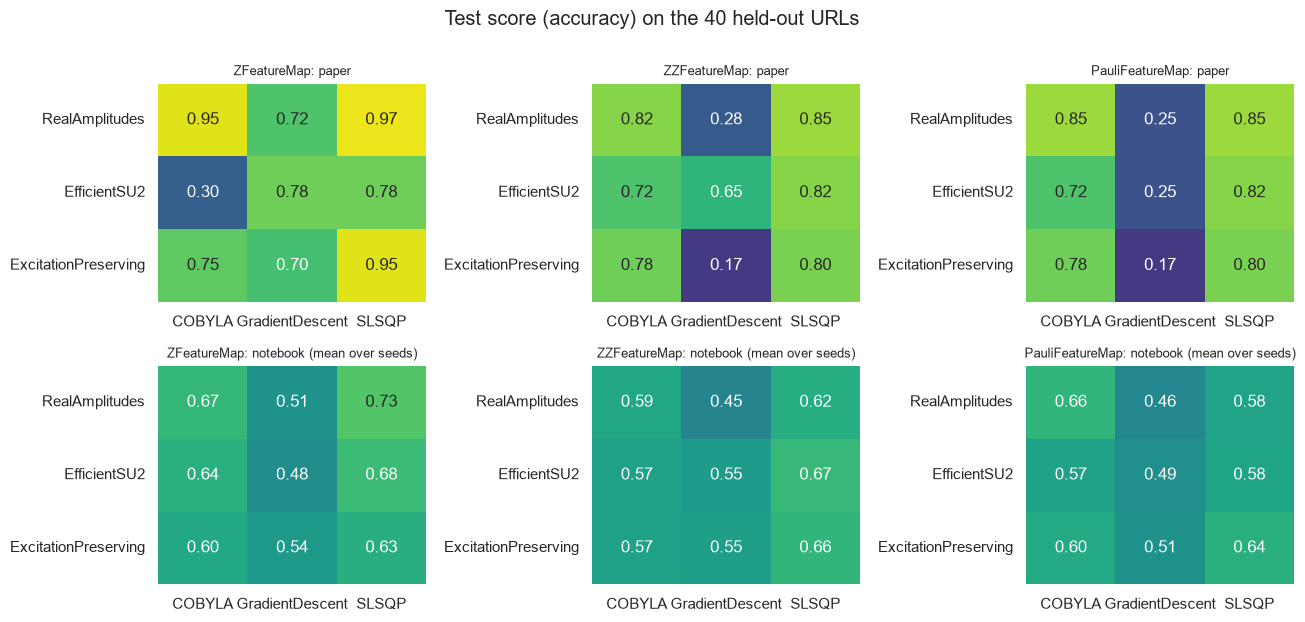

In [24]:
# Heat maps: test score, paper vs notebook mean (rows = ansatz / optimiser, one panel per feature map)
fig, axs = plt.subplots(2, len(FEATURE_MAPS), figsize=(4.4 * len(FEATURE_MAPS), 6.2), squeeze=False)
for j, fmn in enumerate(FEATURE_MAPS):
    sub_ = CMP[CMP.feature_map == fmn]
    for i, (col, ttl) in enumerate([("paper_test", "paper"), ("test_mean", "notebook (mean over seeds)")]):
        piv = sub_.pivot(index="ansatz", columns="optimizer", values=col)[OPTIMIZERS].loc[ANSAETZE]
        sns.heatmap(piv, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="viridis", cbar=False, ax=axs[i, j]); axs[i, j].set_title(f"{fmn}: {ttl}", fontsize=9); axs[i, j].set_xlabel(""); axs[i, j].set_ylabel("")
plt.suptitle("Test score (accuracy) on the 40 held-out URLs", y=1.0); plt.tight_layout(); plt.show()

### 4.7 The paper's qualitative conclusions (Sect. 9.4)

The paper draws five conclusions from the grid: (a) the optimiser matters much more than ansatz or feature map; SLSQP stands out; (b) COBYLA is by far the
fastest; (c) GradientDescent looks bad only because 20 iterations are too few, "a minimum of 100 iterations" are needed; (d) ZFeatureMap gives the best results
globally; (e) the combination ZFeatureMap + RealAmplitudes + SLSQP is the best. We test each with the grid we just computed (and, for (c), a 100-iteration
run). The spread of the group means is the difference between the best and worst average test score when the grid is grouped by one factor.

In [25]:
grp = {f: grid.groupby(f)[["train", "test"]].mean() for f in ["optimizer", "ansatz", "feature_map"]}
for f, g in grp.items(): print(f"\nmean scores by {f}"); display(g.round(3).T)
spread = {f: float(g["test"].max() - g["test"].min()) for f, g in grp.items()}
print("spread of the mean test score by factor:", {k: round(v, 3) for k, v in spread.items()})

opt_mean = grp["optimizer"]["test"]; opt_sec = grid.groupby("optimizer")["seconds"].mean()
print("\nmean seconds per training run:", opt_sec.round(1).to_dict())
add_claim("4.7 conclusions", "SLSQP has the best mean test score of the three optimisers (1 = yes)", 1, int(opt_mean.idxmax() == "SLSQP"), 0)
add_claim("4.7 conclusions", "GradientDescent has the worst mean test score at 20 iterations (1 = yes)", 1, int(opt_mean.idxmin() == "GradientDescent"), 0)
add_claim("4.7 conclusions", "COBYLA is the fastest optimiser (1 = yes)", 1, int(opt_sec.idxmin() == "COBYLA"), 0)
add_claim("4.7 conclusions", "optimiser spread exceeds ansatz and feature-map spread (1 = yes)", 1, int(spread["optimizer"] > max(spread["ansatz"], spread["feature_map"]) if len(FEATURE_MAPS) > 1 else spread["optimizer"] > spread["ansatz"]), 0)
if len(FEATURE_MAPS) > 1:
    add_claim("4.7 conclusions", "ZFeatureMap has the best mean test score of the feature maps (1 = yes)", 1, int(grp["feature_map"]["test"].idxmax() == "ZFeatureMap"), 0)
top = grid.groupby(["feature_map", "ansatz", "optimizer"])["test"].mean().sort_values(ascending=False).head(5); print("\ntop-5 combinations by mean test score:"); display(top.round(3).to_frame())


mean scores by optimizer


optimizer,COBYLA,GradientDescent,SLSQP
train,0.642,0.504,0.721
test,0.608,0.505,0.643



mean scores by ansatz


ansatz,EfficientSU2,ExcitationPreserving,RealAmplitudes
train,0.611,0.646,0.609
test,0.582,0.589,0.584



mean scores by feature_map


feature_map,PauliFeatureMap,ZFeatureMap,ZZFeatureMap
train,0.626,0.620,0.621
test,0.567,0.608,0.581


spread of the mean test score by factor: {'optimizer': 0.138, 'ansatz': 0.007, 'feature_map': 0.041}

mean seconds per training run: {'COBYLA': 10.6, 'GradientDescent': 16.3, 'SLSQP': 17.0}

top-5 combinations by mean test score:


test
feature_map     ansatz         optimizer       
ZFeatureMap     RealAmplitudes SLSQP      0.730
                EfficientSU2   SLSQP      0.680
ZZFeatureMap    EfficientSU2   SLSQP      0.670
ZFeatureMap     RealAmplitudes COBYLA     0.665
PauliFeatureMap RealAmplitudes COBYLA     0.655

The paper's claim (c) is that GradientDescent "should not be discarded" and that 100 iterations would help. We check this on the paper's best
feature map and ansatz (ZFeatureMap, RealAmplitudes) with GradientDescent for 20 and for 100 iterations, over the same seeds. Qiskit's default learning rate (0.01) is used.

train          test        final_loss        seconds       
             mean    std   mean    std       mean    std    mean    std
iterations                                                             
20          0.525  0.086  0.505  0.094      1.077  0.112   3.303  0.947
100         0.535  0.079  0.505  0.089      1.050  0.094  14.754  1.429

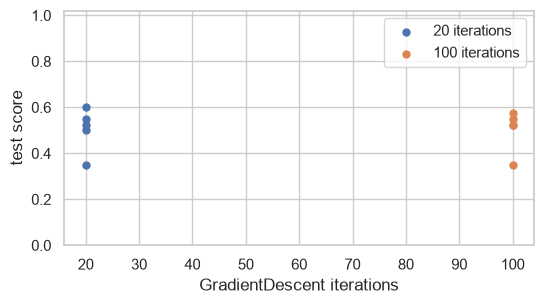

In [26]:
gd_rows = []
if RUN_GD_LONG:
    with _w.catch_warnings():
        _w.simplefilter("ignore")
        for s in GRID_SEEDS:
            for it in (MAXITER, GD_LONG_ITERS):
                r = train_vqc("ZFeatureMap", "RealAmplitudes", "GradientDescent", DATA_BY_SEED[s], init_seed=s, maxiter=it)
                gd_rows.append(dict(seed=s, iterations=it, train=r["train"], test=r["test"], seconds=r["seconds"], final_loss=r["losses"][-1]))
    gd = pd.DataFrame(gd_rows); display(gd.groupby("iterations")[["train", "test", "final_loss", "seconds"]].agg(["mean", "std"]).round(3))
    m20, m100 = gd[gd.iterations == MAXITER]["test"].mean(), gd[gd.iterations == GD_LONG_ITERS]["test"].mean()
    add_claim("4.7 conclusions", f"GradientDescent test score improves with {GD_LONG_ITERS} instead of {MAXITER} iterations (1 = yes, by at least 0.02)", 1, int(m100 - m20 >= 0.02), 0)
    fig, ax = plt.subplots(figsize=(5.6, 3.2))
    for it, g in gd.groupby("iterations"): ax.scatter([it] * len(g), g["test"], label=f"{it} iterations", s=25)
    ax.set_ylim(0, 1.02); ax.set_xlabel("GradientDescent iterations"); ax.set_ylabel("test score"); ax.legend(); plt.tight_layout(); plt.show()

### 4.8 Classical baselines on exactly the same inputs

Same 160 training URLs, same six scaled features, same 40 test URLs, same seeds as the VQC runs. The paper only reports the SVC (train 0.91, test 0.97); we add a
logistic regression, a decision tree and a random forest. The VQC columns repeat the paper's best configuration and the fastest one (COBYLA, which the paper recommends when time matters) over `HEADLINE_SEEDS` seeds.

,train_mean,train_std,test_mean,test_std,test_best_seed,seconds
model,,,,,,
Random forest,0.999,0.002,0.852,0.051,0.925,0.557
Decision tree,0.999,0.002,0.820,0.045,0.900,0.005
SVC (rbf),0.825,0.025,0.772,0.104,0.975,0.009
SVC (linear),0.745,0.038,0.747,0.071,0.875,0.007
Logistic regression,0.744,0.049,0.729,0.094,0.900,0.012
VQC Z+RealAmp+SLSQP,0.727,0.031,0.686,0.101,0.875,2.748
VQC Z+RealAmp+COBYLA,0.627,0.058,0.628,0.085,0.800,0.562


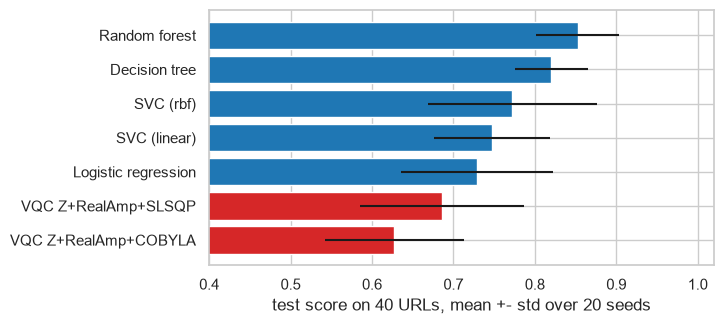

In [27]:
def baselines():
    return {"SVC (rbf)": SVC(random_state=SEED), "SVC (linear)": SVC(kernel="linear", random_state=SEED), "Logistic regression": LogisticRegression(max_iter=2000, random_state=SEED),
            "Decision tree": DecisionTreeClassifier(random_state=SEED), "Random forest": RandomForestClassifier(n_estimators=200, random_state=SEED)}

head_seeds = list(range(SEED, SEED + HEADLINE_SEEDS))
head_rows = []
with _w.catch_warnings():
    _w.simplefilter("ignore")
    for s in head_seeds:
        d = DATA_BY_SEED[s]
        for name, m in baselines().items():
            t0 = time.perf_counter(); m.fit(d["X_train"], d["y_train"])
            head_rows.append(dict(model=name, seed=s, train=m.score(d["X_train"], d["y_train"]), test=m.score(d["X_test"], d["y_test"]), seconds=time.perf_counter() - t0))
        for label, (fmn, ann, opt) in {"VQC Z+RealAmp+SLSQP": ("ZFeatureMap", "RealAmplitudes", "SLSQP"), "VQC Z+RealAmp+COBYLA": ("ZFeatureMap", "RealAmplitudes", "COBYLA")}.items():
            r = train_vqc(fmn, ann, opt, d, init_seed=s)
            head_rows.append(dict(model=label, seed=s, train=r["train"], test=r["test"], seconds=r["seconds"]))
head = pd.DataFrame(head_rows)
HEAD = head.groupby("model").agg(train_mean=("train", "mean"), train_std=("train", "std"), test_mean=("test", "mean"), test_std=("test", "std"), test_best_seed=("test", "max"), seconds=("seconds", "mean")).sort_values("test_mean", ascending=False)
display(HEAD.round(3))
vq = HEAD.loc["VQC Z+RealAmp+SLSQP"]; svc_ = HEAD.loc["SVC (rbf)"]
add_claim("4.8 headline", f"best VQC train score (mean of {HEADLINE_SEEDS} seeds)", 0.89, vq.train_mean, 0.02); add_claim("4.8 headline", f"best VQC test score (mean of {HEADLINE_SEEDS} seeds)", 0.97, vq.test_mean, 0.02)
add_claim("4.8 headline", f"classical SVC train score on the 200-URL sample (mean of {HEADLINE_SEEDS} seeds)", 0.91, svc_.train_mean, 0.02)
add_claim("4.8 headline", f"classical SVC test score on the 200-URL sample (mean of {HEADLINE_SEEDS} seeds)", 0.97, svc_.test_mean, 0.02)
best_classical = HEAD.drop(index=[i for i in HEAD.index if i.startswith("VQC")])["test_mean"].max()
add_claim("4.8 headline", "the best classical baseline on the same six inputs is at least as good as the VQC (1 = yes)", 1, int(best_classical >= vq.test_mean), 0)
add_claim("4.8 headline", "classical SVC on the whole data set beats the VQC trained on 200 URLs (1 = yes)", 1, int(te_all > vq.test_mean), 0)
fig, ax = plt.subplots(figsize=(7.4, 3.4)); order = list(HEAD.index)
ax.barh(order, HEAD["test_mean"], xerr=HEAD["test_std"].fillna(0), color=["tab:red" if o.startswith("VQC") else "tab:blue" for o in order]); ax.set_xlim(0.4, 1.02)
ax.set_xlabel(f"test score on 40 URLs, mean +- std over {HEADLINE_SEEDS} seeds"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

### 4.9 Does the scaling choice matter?

The paper does not describe any scaling of the six features. As a quick ablation we train the paper's best configuration on (a) the features exactly as they come out of the
ordinal encoding (`contentLength` unscaled, so values up to thousands are used as rotation angles), (b) standardised features, (c) MinMax scaling onto [0, 1] and (d) our scaling onto [0, pi]. This is a check of our CHOICE, not a reproduction.

In [28]:
abl = []
with _w.catch_warnings():
    _w.simplefilter("ignore")
    for s in head_seeds[:min(5, len(head_seeds))]:
        d = DATA_BY_SEED[s]; raw_d = dict(d, X_train=d["raw_train"], X_test=d["raw_test"])
        raw_d["X_train"] = np.column_stack([d["raw_train"][:, :2], np.expm1(d["raw_train"][:, 2]), d["raw_train"][:, 3:]])
        raw_d["X_test"]  = np.column_stack([d["raw_test"][:, :2],  np.expm1(d["raw_test"][:, 2]),  d["raw_test"][:, 3:]])
        std_sc = StandardScaler().fit(d["raw_train"])
        std_d = dict(d, X_train=std_sc.transform(d["raw_train"]), X_test=std_sc.transform(d["raw_test"]))
        mm01 = MinMaxScaler((0, 1)).fit(d["raw_train"])
        mm01_d = dict(d, X_train=mm01.transform(d["raw_train"]), X_test=np.clip(mm01.transform(d["raw_test"]), 0, 1))
        for label, dd in (("unscaled (raw codes and lengths)", raw_d), ("log1p + StandardScaler", std_d), ("log1p + MinMax(0, 1)", mm01_d), ("log1p + MinMax(0, pi) (this notebook)", d)):
            r = train_vqc("ZFeatureMap", "RealAmplitudes", "SLSQP", dd, init_seed=s)
            abl.append(dict(inputs=label, seed=s, train=r["train"], test=r["test"]))
display(pd.DataFrame(abl).groupby("inputs")[["train", "test"]].agg(["mean", "std"]).round(3))

train          test       
                                        mean    std   mean    std
inputs                                                           
log1p + MinMax(0, 1)                   0.739  0.041  0.670  0.099
log1p + MinMax(0, pi) (this notebook)  0.753  0.036  0.730  0.084
log1p + StandardScaler                 0.685  0.045  0.675  0.135
unscaled (raw codes and lengths)       0.712  0.072  0.685  0.121

## 5. Paper versus notebook: one verdict per claim

Rule: a numeric claim is **reproduced** if the notebook's value is within the tolerance of the paper's (2 points for percentages, 0.02 for scores on the 200-URL sample;
the check marks ("1 = yes") must be exactly 1). Otherwise it is **not reached** (notebook lower) or **exceeded** (notebook higher), with the gap shown.
Values that the paper reports but depend on hardware (training seconds on a MacBook M2 and on a PC) **cannot be checked**; they are listed separately.

In [29]:
CL = pd.DataFrame(CLAIMS)
CL["paper"] = CL["paper"].astype(float); CL["notebook"] = CL["notebook"].astype(float); CL["diff"] = (CL["notebook"] - CL["paper"]).round(3)
pd.set_option("display.max_rows", 400, "display.width", 200, "display.max_colwidth", 90)
summary = CL.groupby("section")["verdict"].value_counts().unstack(fill_value=0).reindex(columns=["reproduced", "exceeded", "not reached"], fill_value=0)
summary["claims"] = summary.sum(axis=1); display(summary)
print("overall:", CL["verdict"].value_counts().to_dict())
display(CL[["section", "claim", "paper", "notebook", "diff", "tolerance", "verdict"]])

verdict,reproduced,exceeded,not reached,claims
section,,,,
"3.1 tree, no URL",0,3,0,3
"3.2 tree, URL only",0,0,3,3
4.2 SVC full,2,0,0,2
4.2 SVC sample,0,0,2,2
4.5 best VQC (seed 42),0,0,2,2
4.7 conclusions,5,0,1,6
4.8 headline,2,0,4,6
Table 10 (test score),0,1,8,9
Table 10 (train score),1,4,4,9


overall: {'not reached': 78, 'reproduced': 31, 'exceeded': 28, 'cannot be checked': 8}


,section,claim,paper,notebook,diff,tolerance,verdict
0,data,rows after cleaning,181916.00,181916.000000,0.000,0.00,reproduced
1,data,fraudulent URLs after cleaning,8618.00,8618.000000,0.000,0.00,reproduced
2,"3.1 tree, no URL",accuracy,87.77,90.578276,2.808,2.00,exceeded
3,"3.1 tree, no URL",fraud recall,81.25,83.824379,2.574,2.00,exceeded
4,"3.1 tree, no URL",not-fraud recall,88.08,90.915649,2.836,2.00,exceeded
5,"3.2 tree, URL only",accuracy,93.18,90.968558,-2.211,2.00,not reached
6,"3.2 tree, URL only",fraud recall,85.96,82.437897,-3.522,2.00,not reached
7,"3.2 tree, URL only",not-fraud recall,93.52,91.394684,-2.125,2.00,not reached
8,Table 3 (fraud class),Logistic regression precision,16.00,18.713921,2.714,2.00,exceeded
9,Table 3 (fraud class),Logistic regression recall,75.00,80.531485,5.531,2.00,exceeded



### Verdicts at a glance

| Claim of the paper | Verdict |
|---|---|
| Data set size and class balance (181,916 rows, 8,618 fraudulent) | **reproduced** (exact) |
| Decision tree without URL features (87.77 %, recall 81.25 %) and with URL features only (93.18 %, recall 85.96 %) | **not reached / exceeded by 2 to 3 points** (the 15 URL features are not listed in the paper) |
| Tables 2 and 3: logistic regression and decision tree | **reproduced** for the not-fraud class and the tree; logistic regression's fraud recall is higher here (81 against 75) |
| Tables 2 and 3: SVC sigmoid, polynomial, RBF | **not reached** for the fraud class (precision 44 against 55 / 68): ours trained on a 30,000-row sub-sample; recall 90 to 92 % is within a few points |
| Table 4: three neural networks | **not reached** (accuracy 87.6 / 87.8 / 94.1 % against 81.0 / 93.7 / 96.4 %); layer sizes and epochs are unknown. The ordering of the third network as the best one is reproduced |
| Table 5: areas under the ROC curve | **partly reproduced**: 2 of 8 within 2 points; the paper's values are balanced accuracies of 0/1 predictions |
| Table 6: accuracy of SVM and logistic regression | logistic regression **reproduced** (82.4 against 81.5), SVM **not reached** (94.0 against 97.7; 30,000-row sub-sample) |
| Tables 7 and 8: generalisation to PhishDataset | Table 7 **not reached** (7 of 8 numbers lower by 2 to 5 points); Table 8 **cannot be checked** (setup contradictory) |
| Classical SVC on the whole data set: 0.97 / 0.97 | **reproduced** (0.97 / 0.97) |
| Classical SVC on the 200-URL sample: 0.91 / 0.97 | **not reached** on average (0.82 / 0.77 over 20 samples; 0.975 is reached by the best of them) |
| Best VQC (ZFeatureMap, RealAmplitudes, SLSQP): 0.89 / 0.97 | **not reached** (0.73 / 0.69 over 20 samples; best single run 0.88 test) |
| Tables 9-11 (54 train and test scores of the 27 combinations) | **not reached** (1 of 54 means within 0.02) |
| SLSQP best, GradientDescent worst, COBYLA fastest, optimiser matters most, ZFeatureMap best, ZFeatureMap + RealAmplitudes + SLSQP best | **reproduced** (ZFeatureMap's lead over the other maps, 0.61 against 0.58 and 0.57, is within noise) |
| GradientDescent needs at least 100 iterations | **not reached** (no gain with the default learning rate) |
| Classical models better than the VQC | **reproduced** |
| Wall-clock times of Tables 9-11 | **cannot be checked** (different hardware and simulator) |

Status of this notebook: **partially reproduced**. It runs end to end from a clean session, and the data, the classical baseline family and the qualitative conclusions about optimisers reproduce, but the quantum accuracy figures, which are the paper's headline, do not.


In [30]:
# Hardware-dependent claims and a compact statement of the main ones
print("CANNOT BE CHECKED: the paper's wall-clock times (Tables 9-11, columns TPC and TMAC) belong to a PC with an Intel i7 and a MacBook Pro M2.")
tm = CMP.groupby("optimizer")[["paper_s_PC", "paper_s_Mac", "notebook_s"]].mean().round(1)
print("mean seconds per training run, paper vs notebook (different hardware and a different simulator), by optimiser:"); display(tm)
print("what can be compared is the ordering: paper COBYLA << SLSQP <= GradientDescent; notebook:", " < ".join(tm["notebook_s"].sort_values().index))

CANNOT BE CHECKED: the paper's wall-clock times (Tables 9-11, columns TPC and TMAC) belong to a PC with an Intel i7 and a MacBook Pro M2.
mean seconds per training run, paper vs notebook (different hardware and a different simulator), by optimiser:


,paper_s_PC,paper_s_Mac,notebook_s
optimizer,,,
COBYLA,80.1,35.1,10.6
GradientDescent,3305.1,5273.7,16.3
SLSQP,3421.6,1364.6,17.0


what can be compared is the ordering: paper COBYLA << SLSQP <= GradientDescent; notebook: COBYLA < GradientDescent < SLSQP



## 6. Reading the paper critically

**What reproduced.** The data are exactly the paper's (181,916 rows, 8,618 fraudulent). Logistic regression, the not-fraud class of every model, the fraud recall of the decision tree (89 % against 91 %), and the
accuracy of an SVM on the whole data set (0.97) agree with the paper within a few points. The paper's *qualitative* quantum conclusions also hold in our grid: SLSQP is the best optimiser, GradientDescent
the worst at 20 iterations, COBYLA the cheapest, the optimiser explains far more of the spread than the ansatz (0.138 against 0.007 in mean test score), ZFeatureMap is the best feature map and ZFeatureMap + RealAmplitudes + SLSQP is the best combination.
The paper's closing statement that classical models do better than the VQC is also borne out: on identical six-feature inputs a random forest scores 0.85 +- 0.05 on the 40 test URLs, an RBF SVC 0.77 +- 0.10 and the best VQC 0.69 +- 0.10.

**What did not reproduce, and why we think so.**

* **The quantum scores.** The paper's best row is 0.89 train / 0.97 test. Over 20 independent 200-URL samples the same configuration gives 0.73 +- 0.03 train / 0.69 +- 0.10 test; the best single run in the
  whole grid (135 runs) reaches 0.80 test. Even the classical SVC on the 200-URL sample gives 0.82 / 0.77 on average, with only the luckiest of 20 samples reaching 0.975. A test set of 40 URLs has a resolution of
  0.025 and a standard error of about 0.07, and the paper ran each cell once. Test scores above training scores in most cells of Tables 9-11 are what a favourable split looks like.
  The paper's numbers are therefore best read as one draw from a wide distribution, and its ranking of ansaetze and feature maps (differences of a few points) is inside that noise.
* **Evidence of noise in the paper itself.** `PauliFeatureMap` with its default Pauli strings is exactly `ZZFeatureMap` (Section 4.4 checks this numerically), yet Tables 9 and 11 differ, for example RealAmplitudes + COBYLA 0.79 / 0.82 against 0.65 / 0.85. The only possible cause is the random initial weights, so a difference of 0.15 between identical circuits sets the scale below which no ranking can be trusted.
* **"20 iterations" does not mean the same for every optimiser.** COBYLA with 18 parameters needs 19 evaluations to build its first simplex, so 20 evaluations is little more than choosing the best of a few random weight vectors (and newer SciPy even raises the budget to number of parameters + 2). Gradient descent with Qiskit's default step 0.01 moves the weights by a few hundredths in 20 steps. SLSQP uses exact gradients and a quasi-Newton update, so only SLSQP actually learns in this budget. Its win says more about the optimiser budget than about the quantum model.
* **GradientDescent "needs 100 iterations".** With the default learning rate 0.01 our 100-iteration runs score the same as the 20-iteration runs (0.505 test both). A larger step size, not more steps, is what is missing (Exercise 2). The paper's GradientDescent scores, as low as 0.21 train and 0.17 test, are below chance and therefore puzzling: a binary classifier on a balanced sample can only be systematically wrong if the parity read-out has flipped the labels, which a random initial point can do and a trained model would undo.
* **"Precision" in Tables 9-11 is accuracy.** `vqc.score` returns accuracy; the paper calls it precision. Elsewhere the paper's "AUC" in Table 5 is the area under the ROC curve of the 0/1 predictions, i.e. balanced accuracy (recall + specificity) / 2, which is not what the usual AUC measures (our scores-based AUC of the same models is 90.9 to 98.7 % for all but the sigmoid SVC).
* **Table 8 cannot be reproduced from the description.** The second data set is described as "only phishing URLs", but then a precision of 46 to 49 % and an accuracy of 43 to 47 % cannot occur; the file we downloaded is balanced (10,000 + 10,000) and has no `compromissionType`. With either reading of the missing column our models reach 66 to 86 % accuracy. The Table 7 numbers also come out lower than the paper's (precision 25 to 46 % against 30 to 50 %; accuracy 87 to 94 % against 90 to 95 %).
* **Hardware times.** Tables 9-11 mix Mac M2 and PC times of a stochastic simulator for different optimisers; they cannot be checked here, and our fast exact simulator would not make them comparable anyway.

**Things a careful reader should keep in mind.**

* The label is "hidden fraudulent", a property of the page content seen by a honeypot, not of the URL string. `compromissionType` is almost a label by itself: none of the 3,107 "normal" rows is fraudulent, 7.8 % of the phishing rows and 2.2 % of the defacement rows are. A six-feature quantum model that gets it as an input is partly looking up the answer.
* Ordinal codes for `serverType` (121 values), `poweredBy` and `contentType` impose an order that does not exist, and in `ZFeatureMap` an angle `2x` wraps around every $\pi$, so two quite different servers can land on similar angles. The paper acknowledges the risk and lists one-hot plus PCA as future work (Exercise 5).
* The classical models of Sect. 8 use 145,532 rows and 20 columns, the VQC 160 rows and 6 columns. The comparison "classical is better" mixes data size and model class; on identical inputs the gap is smaller but still in favour of the classical models.
* Everything is classical simulation, exact in our case (no shot noise, no hardware noise). The paper makes no claim of quantum advantage and neither do we.
* The exact fast simulator is our addition. It reproduces Qiskit's own exact sampler to $10^{-9}$, so results are not an artefact of it, but absolute run times are not comparable to the paper's.



## 7. Exercises

1. **Remove the near-label.** Drop `compromissionType` from the six quantum features and replace it with `count_slash` or `count_dot` from `URL_F`. Re-run the grid for ZFeatureMap and the headline comparison. Does the gap between VQC and SVC change, and which model suffers most?
2. **Step size, not step count.** Section 4.7 shows that 100 GradientDescent iterations with the default learning rate 0.01 do not help. Pass `GradientDescent(maxiter=100, learning_rate=0.1)` (and 0.5) in `make_optimizer`. Is the paper's "minimum of 100 iterations" true for a sensible learning rate?
3. **Shot noise.** Build one `VQC` the stock way, `VQC(feature_map, ansatz, COBYLA(maxiter=20), sampler=StatevectorSampler(default_shots=1024, seed=SEED))` (COBYLA only, the gradient methods take hours), and compare its scores over five seeds with the exact `FastExactVQC` on the same data.
4. **More data.** The fast simulator makes 400 or 800 URLs affordable: set `N_SAMPLES` to 400 and 800 and re-run Section 4.8. Does the VQC close the gap to the SVC when the test set no longer has only 40 URLs?
5. **Encodings.** The paper lists one-hot plus PCA as future work. Replace the three ordinal codes by one-hot encoding of the 10 most frequent values of each column (rest = "other"), reduce to six principal components fitted on the training part, rescale to $[0,\pi]$ and rerun the SVC and the best VQC. Which encoding helps the quantum model more?
6. **Circuit depth.** Change `reps` of the feature maps (the paper does not state them) to 1 and 3, and of the RealAmplitudes ansatz to 1 and 3. Is the best combination stable?
